# Premier League Analytics · 2015/16 – 2024/25

**Done by Chin Guan Chung**

**Ten seasons · 5 questions · 4 machine-learning experiments · a real FPL squad · a check against the actual 2025/26 season**

This notebook uses public data from the last ten completed Premier League seasons to answer five questions. Each question section follows the same pattern:

> **Question → Method → Exploratory charts → Interactive dashboard → Result**

| # | Question | How it is answered | Section |
|:-:|---|---|:-:|
| **Q1** | Which is the best club? | A weighted **Club Score (0–100)** over 10 seasons, plus a check of whether the leader changes under other weightings | §2 |
| **Q2** | Who are the best players? | Career **FPL points** (all-round output) and an **Attacking Score** built from goals, xG, assists and xA per 90 minutes | §3 |
| **Q3** | What is the best starting XI? | **Experiment 1**: a gradient-boosting model predicts next-season FPL points (with an 80% range). An optimiser picks the best XI, and a £100m FPL-legal squad with a weekly captain plan | §4 |
| **Q4** | What will player prices be next season? | **Experiment 2**: a random forest projects 2025/26 FPL prices | §5 |
| **Q5** | How much does home advantage matter, and how predictable are matches? | Season-by-season trends, plus **Experiment 3** (result classifier, with a calibration check) and **Experiment 4** (goals model), both using form, Elo ratings and betting odds | §6 |

**§7 Reality check** then tests every forecast against the actual 2025/26 season, which none of the models saw, and all the answers are collected in **§8 Final results**. **§9** exports the interactive charts to a stand-alone web page.

## How to read this notebook

**Project layout.** The reusable code (theme, data loaders, feature engineering, models) lives in the `pl_analytics/` package next to this notebook, and `tests/` checks it with `pytest`. This notebook tells the story: it calls those functions, shows the charts, and writes every "Key takeaways" block from the computed results, so no number in the text is typed by hand.

**Run it top to bottom.** The first run downloads about 40 public CSV files and caches them in `data_cache/`. Later runs work offline.

**Key terms**

| Term | Meaning |
|---|---|
| **FPL** | Fantasy Premier League, the official fantasy game. Players score points for minutes, goals, assists, clean sheets, saves and bonus. *Price* means the FPL game price (£m), **not** a transfer fee. |
| **xG / xA** | Expected goals and expected assists: the probability that a shot (or the pass before it) produces a goal, based on shot quality. |
| **PPM** | Points per match. |
| **Holdout** | Seasons kept out of training to test a model. Every model here is tested on *later* seasons than it was trained on (no shuffling across time). |
| **Baseline** | A deliberately simple prediction, such as "same as last season". A model is only useful if it beats its baseline. |

**Data sources**

| Data | Used for | Source |
|---|---|---|
| Match results & stats (one CSV per season, league `E0`) | Tables, Club Score, home advantage, match models | [football-data.co.uk](https://www.football-data.co.uk/englandm.php) |
| FPL player-season exports (2016/17 – 2024/25) | Player points, positions, clubs, prices | [vaastav/Fantasy-Premier-League](https://github.com/vaastav/Fantasy-Premier-League) |
| Understat player-season aggregates | Goals, xG, assists, xA, minutes | [understat_players_aggregated](https://github.com/vibedatascience/understat_players_aggregated) |

> **Scope note:** the FPL archive starts in 2016/17, so the player models use nine seasons. The 2025/26 player projections are made *on the eve of 2025/26*: they use 2024/25 statistics plus the Gameweek 1 squad lists (who is registered, at which club, at what price), which were published before the season started. §7 then checks them against what actually happened.

---
# 0 · Setup

This section installs and imports the libraries, then sets up the **Premier League visual theme** that every chart below uses:

* **Plotly**: a custom `premier_league` template (PL purple text, magenta/cyan/green accents, purple hover labels, clean grid).
* **Matplotlib / seaborn**: matching `rcParams`, a PL colour map, and a purple header strip on each figure.
* **Tables & results**: purple-header tables and highlighted *result cards*, styled like the PL website.

### 0.1 · Install and import libraries

In [1]:
# Install the exact library versions this project was tested with (skip if already installed).
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# ── Standard library ─────────────────────────────────────────────────────────
import warnings

# ── Data handling and plotting ───────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import display, HTML

# ── Machine learning (scikit-learn) ──────────────────────────────────────────
from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, f1_score, log_loss, classification_report, confusion_matrix,
    mean_absolute_error, mean_squared_error, mean_poisson_deviance, r2_score,
)

# ── This project's own package (pl_analytics/) ───────────────────────────────
from pl_analytics.theme import *          # PL colours, Plotly template, chart / table / takeaway helpers
from pl_analytics.data import *           # configuration and data loaders
from pl_analytics.features import *       # league tables, Club Score, match and player features
from pl_analytics.models import *         # pipelines, XI / FPL-squad optimisers, calibration
from pl_analytics.charts import draw_xi_pitch
from pl_analytics.dashboard import write_dashboard

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
warnings.filterwarnings("ignore", category=FutureWarning)

print(f"Libraries ready · pandas {pd.__version__} · plotly {plotly.__version__} · random seed {RANDOM_STATE}")

Libraries ready · pandas 2.3.3 · plotly 6.8.0 · random seed 42


### 0.2 · Premier League visual theme

The theme is defined in `pl_analytics/theme.py` and applied by the import above.

The palette uses the Premier League brand colours: deep **purple** `#37003C`, **magenta** `#E90052`, **cyan** `#04F5FF` and **green** `#00FF85`. Cyan and green are slightly deepened for lines on a white background so they stay readable. Position colours follow the FPL convention, and club colours are used wherever a chart compares clubs.

In [3]:
# The theme was registered when pl_analytics.theme was imported; show the palette as a quick check.
stat_tiles([(name, PL[name]) for name in ["purple", "pink", "cyan", "green"]])
print(f"Plotly template: {pio.templates.default}")

Plotly template: premier_league


### 0.3 · Configuration and helper functions

Everything you might want to change (seasons, source URLs, cache folder) is set in `pl_analytics/data.py`, together with the helpers for cached downloads, season labels and name normalisation. This cell only sets up the two collections that the rest of the notebook fills in.

In [4]:
# Results collected as the notebook runs, then summarised in §8
EXPERIMENT_RESULTS = []   # one row per ML experiment: model score vs baseline score
FINAL_ANSWERS = {}        # Q1…Q5 → (kicker, headline, detail) for the final result cards


def add_experiment_result(experiment, question, target, model, metric, model_score, baseline, baseline_score,
                          higher_is_better):
    """Record one experiment's headline metric next to its baseline for the §8 scorecard."""
    gain = (model_score - baseline_score) if higher_is_better else (baseline_score - model_score)
    EXPERIMENT_RESULTS.append({
        "Experiment": experiment, "Question": question, "Target": target, "Model": model, "Metric": metric,
        "Model score": round(model_score, 3), "Baseline": baseline, "Baseline score": round(baseline_score, 3),
        "Improvement": f"{gain / abs(baseline_score):+.1%}" if baseline_score else "n/a",
        "Beats baseline": "✅" if gain > 0 else "❌",
    })


print(f"Seasons: {SEASON_LABELS[0]} → {SEASON_LABELS[-1]} ({len(SEASON_LABELS)} seasons) · cache: {CACHE_DIR.name}/")

Seasons: 2015-16 → 2024-25 (10 seasons) · cache: data_cache/


---
# 1 · Load the data

Three sources are loaded and cleaned into tidy tables:

| Table | Grain | Built from |
|---|---|---|
| `matches` | one row per match | football-data.co.uk |
| `fpl_players` | one row per player per season | FPL `players_raw.csv` + `teams.csv` |
| `understat_players` | one row per player per season | Understat aggregates |

Each loader reports what it loaded and skips (rather than crashes on) a season that is temporarily unavailable.

### 1.1 · Match results (football-data.co.uk)

In [5]:
matches, match_load_report = load_matches(SEASON_LABELS)        # pl_analytics/data.py

print(f"✓ Match data: {(match_load_report['status'] == 'OK').sum()}/{len(SEASON_LABELS)} seasons · {len(matches):,} matches")
failed = match_load_report[match_load_report["status"] != "OK"]
if not failed.empty:
    display(failed)
display(pl_table(matches[["season", "match_date", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "FTR"]].head(5)
                 .assign(match_date=lambda d: d["match_date"].dt.date), highlight_first=False))

✓ Match data: 10/10 seasons · 3,800 matches


season,match_date,HomeTeam,AwayTeam,FTHG,FTAG,FTR
2015-16,2015-08-08,Bournemouth,Aston Villa,0,1,A
2015-16,2015-08-08,Chelsea,Swansea,2,2,D
2015-16,2015-08-08,Everton,Watford,2,2,D
2015-16,2015-08-08,Leicester,Sunderland,4,2,H
2015-16,2015-08-08,Man United,Tottenham,1,0,H


### 1.2 · Fantasy Premier League player-seasons

`players_raw.csv` is the full FPL export. It stores position (`element_type` 1–4) and club (`team` 1–20) as numeric IDs. Club IDs are converted to names with `teams.csv`, which exists from 2019/20 onwards. For earlier seasons, the lookup is rebuilt from the fact that FPL numbers clubs **alphabetically**, using that season's 20 clubs from the match data. Prices are stored in tenths of a million (`125` = £12.5m) and converted to £m.

In [6]:
fpl_raw, fpl_load_report = load_fpl_raw(FPL_SEASONS, matches)  # club IDs → names via teams.csv / alphabetical rebuild

print(f"✓ FPL data: {(fpl_load_report['status'] == 'OK').sum()}/{len(FPL_SEASONS)} seasons · raw shape {fpl_raw.shape}")
failed = fpl_load_report[fpl_load_report["status"] != "OK"]
if not failed.empty:
    display(failed)

✓ FPL data: 9/9 seasons · raw shape (6517, 111)


In [7]:
fpl_players = clean_fpl_players(fpl_raw) if not fpl_raw.empty else pd.DataFrame()

if not fpl_players.empty:
    print(f"✓ Clean FPL player-seasons: {len(fpl_players):,} · seasons: {fpl_players['season'].nunique()}")
    display(pd.crosstab(fpl_players["season"], fpl_players["position"])[POS_ORDER].T)   # sanity check: no UNK
    display(pl_table(fpl_players[["player", "position", "team", "season", "total_points", "minutes", "now_cost"]]
                     .sort_values("total_points", ascending=False).head(5)))
else:
    print("No FPL files loaded; the player sections (§3–§5) will be skipped.")

✓ Clean FPL player-seasons: 6,497 · seasons: 9


season,2016-17,2017-18,2018-19,2019-20,2020-21,2021-22,2022-23,2023-24,2024-25
position,,,,,,,,,
GK,73,68,64,73,80,83,85,100,82
DEF,214,214,217,224,246,247,262,278,268
MID,292,271,252,277,295,309,338,374,347
FWD,104,94,91,92,92,98,93,113,87


player,position,team,season,total_points,minutes,now_cost
Mohamed Salah,MID,Liverpool,2024-25,344,"3,374",13.60
Mohamed Salah,MID,Liverpool,2017-18,303,"2,905",10.60
Erling Haaland,FWD,Man City,2022-23,272,"2,767",12.40
Mohamed Salah,MID,Liverpool,2021-22,265,"2,758",13.10
Alexis Sánchez,MID,Arsenal,2016-17,264,"3,217",11.70


### 1.2b · Pre-season squads (Gameweek 1)

End-of-season files show where a player *finished* the season. A forecast, though, has to be made *before* the season, using the squads as they stood then. The FPL Gameweek 1 file is that snapshot: every player registered when the season kicked off, with their club and starting price. It is used in three ways:

1. **Who to forecast.** Only players in the next season's GW1 squad list are projected, so players who left the league in the summer are dropped.
2. **Which club.** Summer signings are projected at their new club (e.g. Mbeumo at Man United for 2025/26).
3. **Pre-season features.** The new club's strength, whether the player changed club, and FPL's starting price.

> The 2025/26 GW1 file is the one piece of 2025/26 data the forecasts use. It was published before a ball was kicked, so the forecasts are now made *on the eve of 2025/26* rather than at the end of 2024/25. Moves completed after GW1 (e.g. Isak's deadline-day transfer) are still invisible. GW1 files before 2020/21 have no club column, so those seasons fall back to the player's FPL club ID for that season.

In [8]:
FORECAST_SEASON = season_label(int(FPL_SEASONS[-1][:4]) + 1)        # 2025-26: the season being forecast
gw1_squads = load_gw1_squads(FPL_SEASONS + [FORECAST_SEASON], matches)

print("Players in the Gameweek-1 squad list per season:")
display(gw1_squads.groupby("season_start_year").size().rename(index=season_label).to_frame("players").T)

Players in the Gameweek-1 squad list per season:


season_start_year,2016-17,2017-18,2018-19,2019-20,2020-21,2021-22,2022-23,2023-24,2024-25,2025-26
players,524,511,525,526,425,554,573,658,616,690


### 1.3 · Understat attacking metrics

The Understat file covers several leagues, so it is filtered to the EPL. A player who moved clubs mid-season has one row per club, so rows are summed per player and season before per-90 rates are calculated.

In [9]:
understat_players = load_understat_players()                       # EPL only, 2015-16 … 2024-25
if not understat_players.empty:
    print(f"✓ Understat EPL player-seasons: {len(understat_players):,} · seasons: {understat_players['year'].nunique()}")

✓ Understat EPL player-seasons: 5,356 · seasons: 10


### 1.4 · The data at a glance

A quick look at the data before the analysis, to check that the totals make sense.

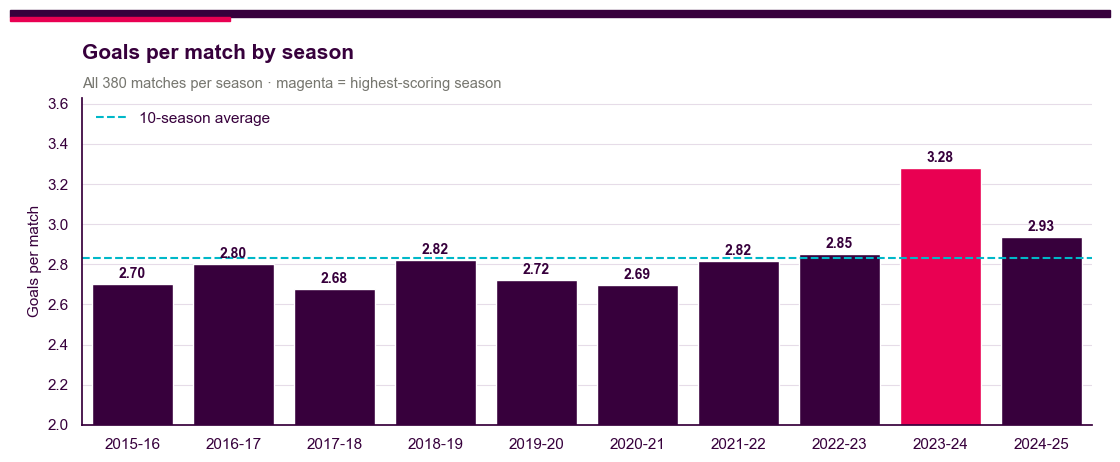

In [10]:
goals_by_season = (matches.assign(goals=matches["FTHG"] + matches["FTAG"])
                   .groupby("season", as_index=False).agg(goals=("goals", "sum"), per_match=("goals", "mean")))

stat_tiles([
    ("Seasons", matches["season"].nunique()),
    ("Matches", f"{len(matches):,}"),
    ("Goals", f"{int(goals_by_season['goals'].sum()):,}"),
    ("Goals / match", f"{goals_by_season['goals'].sum() / len(matches):.2f}"),
    ("Clubs", matches["HomeTeam"].nunique()),
    ("FPL player-seasons", f"{len(fpl_players):,}"),
])

# EDA: goals per match by season. The highest-scoring season is highlighted in magenta.
fig, ax = plt.subplots(figsize=(11, 4.6))
peak = goals_by_season["per_match"].idxmax()
colors = [PL["pink"] if i == peak else PL["purple"] for i in goals_by_season.index]
sns.barplot(data=goals_by_season, x="season", y="per_match", hue="season", palette=colors, legend=False, saturation=1, ax=ax)
for i, v in enumerate(goals_by_season["per_match"]):
    ax.text(i, v + 0.03, f"{v:.2f}", ha="center", fontweight="bold", fontsize=10)
ax.axhline(goals_by_season["per_match"].mean(), color=PL["cyan_dk"], ls="--", lw=1.5, label="10-season average")
ax.set(xlabel="", ylabel="Goals per match", ylim=(2, goals_by_season["per_match"].max() + 0.35))
ax.legend(loc="upper left")
pl_mpl_title(ax, "Goals per match by season", "All 380 matches per season · magenta = highest-scoring season")
show_mpl(fig)

---
# 2 · Q1: Which is the best club?

**Method.** Each season's league table is rebuilt from the match results. Six club metrics are then combined into one **Club Score** for the 10-season window. Each metric is min-max scaled to 0–1 so that unlike units can be blended, and then weighted:

| Metric | Weight | Why |
|---|:-:|---|
| Total points | 30% | Rewards sustained success across all 10 seasons |
| Points per match | 25% | Quality per game, regardless of seasons played |
| League titles | 20% | The trophy that defines a "best" club |
| Top-four finishes | 10% | Consistent Champions League qualification |
| Goal difference per match | 10% | How dominant the results were |
| Win rate | 5% | Ability to turn draws into wins |

The weights are a judgement call, so §2.5 checks whether the winner changes under three alternative weightings.

### 2.1 · Rebuild every league table

In [11]:
season_standings = build_season_standings(matches)               # every season's table, rebuilt from results

# Champions and their winning margin, season by season
top_two = season_standings[season_standings["Position"] <= 2].pivot(index="season", columns="Position")
champions = pd.DataFrame({
    "Season": top_two.index,
    "Champion": top_two[("team", 1)].values,
    "Points": top_two[("Points", 1)].values,
    "Runner-up": top_two[("team", 2)].values,
    "Margin (pts)": (top_two[("Points", 1)] - top_two[("Points", 2)]).values,
})
display(pl_table(champions, highlight_first=False))

Season,Champion,Points,Runner-up,Margin (pts)
2015-16,Leicester,81,Arsenal,10
2016-17,Chelsea,93,Tottenham,7
2017-18,Man City,100,Man United,19
2018-19,Man City,98,Liverpool,1
2019-20,Liverpool,99,Man City,18
2020-21,Man City,86,Man United,12
2021-22,Man City,93,Liverpool,1
2022-23,Man City,89,Arsenal,5
2023-24,Man City,91,Arsenal,2
2024-25,Liverpool,84,Arsenal,10


### 2.2 · Calculate the Club Score

In [12]:
club_summary = (
    season_standings.groupby("team", as_index=False)
    .agg(Seasons=("season", "nunique"), Total_points=("Points", "sum"),
         Avg_points_per_match=("Points_per_match", "mean"),
         Titles=("Position", lambda x: int((x == 1).sum())),
         Top4_finishes=("Position", lambda x: int((x <= 4).sum())),
         Goal_difference_per_match=("GD_per_match", "mean"), Win_rate=("Win_rate", "mean"),
         Best_finish=("Position", "min"))
)

score_weights = {
    "Total_points": 0.30, "Avg_points_per_match": 0.25, "Titles": 0.20,
    "Top4_finishes": 0.10, "Goal_difference_per_match": 0.10, "Win_rate": 0.05,
}


club_summary["Club_score"] = compute_club_score(club_summary, score_weights)
club_summary = club_summary.sort_values(["Club_score", "Total_points"], ascending=False).reset_index(drop=True)
club_summary.insert(0, "Rank", np.arange(1, len(club_summary) + 1))

display(pl_table(
    club_summary[["Rank", "team", "Club_score", "Seasons", "Total_points", "Avg_points_per_match", "Titles",
                  "Top4_finishes", "Goal_difference_per_match", "Win_rate"]].head(12)
    .rename(columns={"team": "Club", "Club_score": "Club Score", "Total_points": "Points", "Avg_points_per_match": "PPM",
                     "Top4_finishes": "Top 4", "Goal_difference_per_match": "GD / match", "Win_rate": "Win %"}),
))

Rank,Club,Club Score,Seasons,Points,PPM,Titles,Top 4,GD / match,Win %
1,Man City,100.00,10,853,2.24,6,10,1.48,0.70
2,Liverpool,78.77,10,801,2.11,2,8,1.12,0.62
3,Chelsea,60.31,10,668,1.76,1,6,0.56,0.51
4,Arsenal,59.43,10,712,1.87,0,4,0.75,0.56
5,Tottenham,55.76,10,660,1.74,0,5,0.64,0.52
6,Man United,53.46,10,657,1.73,0,4,0.40,0.49
7,Leicester,38.66,9,463,1.35,1,1,-0.00,0.38
8,Newcastle,35.00,9,461,1.35,0,1,-0.03,0.37
9,West Ham,34.03,10,496,1.31,0,0,-0.15,0.35
10,Everton,33.48,10,490,1.29,0,0,-0.15,0.34


### 2.3 · Exploratory charts

The **bar chart** ranks the clubs by Club Score, and the **heatmap** shows every club's finishing position by season. Darker cells are higher finishes, and blank cells are seasons outside the Premier League.

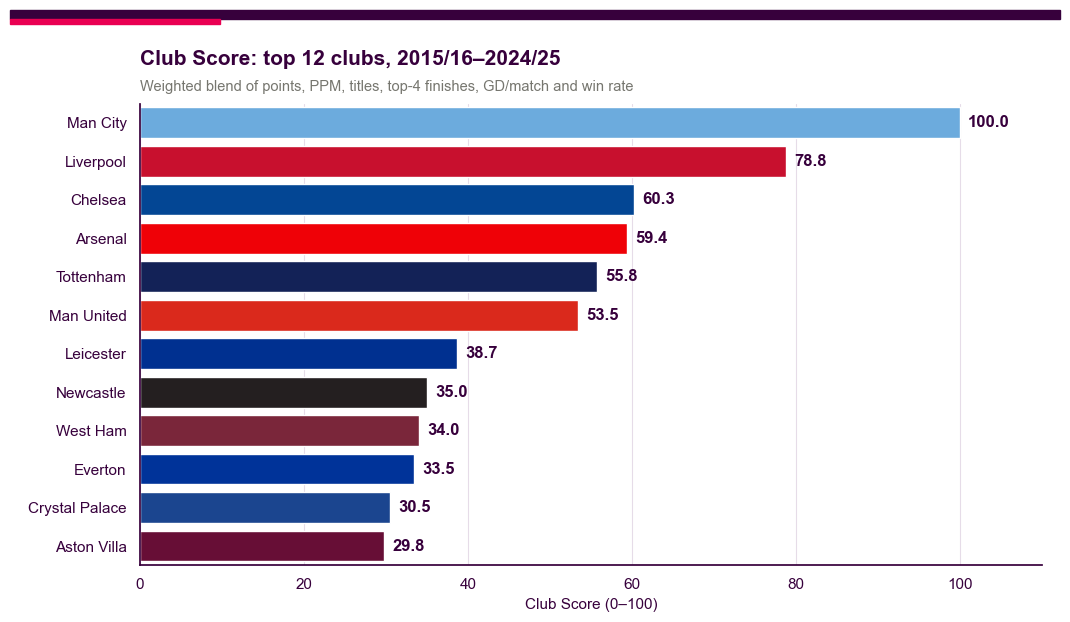

In [13]:
# Bar chart of the top 12 clubs, each bar in its kit colour
top_clubs = club_summary.head(12)
fig, ax = plt.subplots(figsize=(10.5, 6.2))
sns.barplot(data=top_clubs, y="team", x="Club_score", hue="team",
            palette={t: club_color(t) for t in top_clubs["team"]}, legend=False, saturation=1, ax=ax)
for i, v in enumerate(top_clubs["Club_score"]):
    ax.text(v + 1, i, f"{v:.1f}", va="center", fontweight="bold")
ax.set(xlabel="Club Score (0–100)", ylabel="", xlim=(0, 110))
ax.grid(axis="y", visible=False)
pl_mpl_title(ax, "Club Score: top 12 clubs, 2015/16–2024/25",
             "Weighted blend of points, PPM, titles, top-4 finishes, GD/match and win rate")
show_mpl(fig)

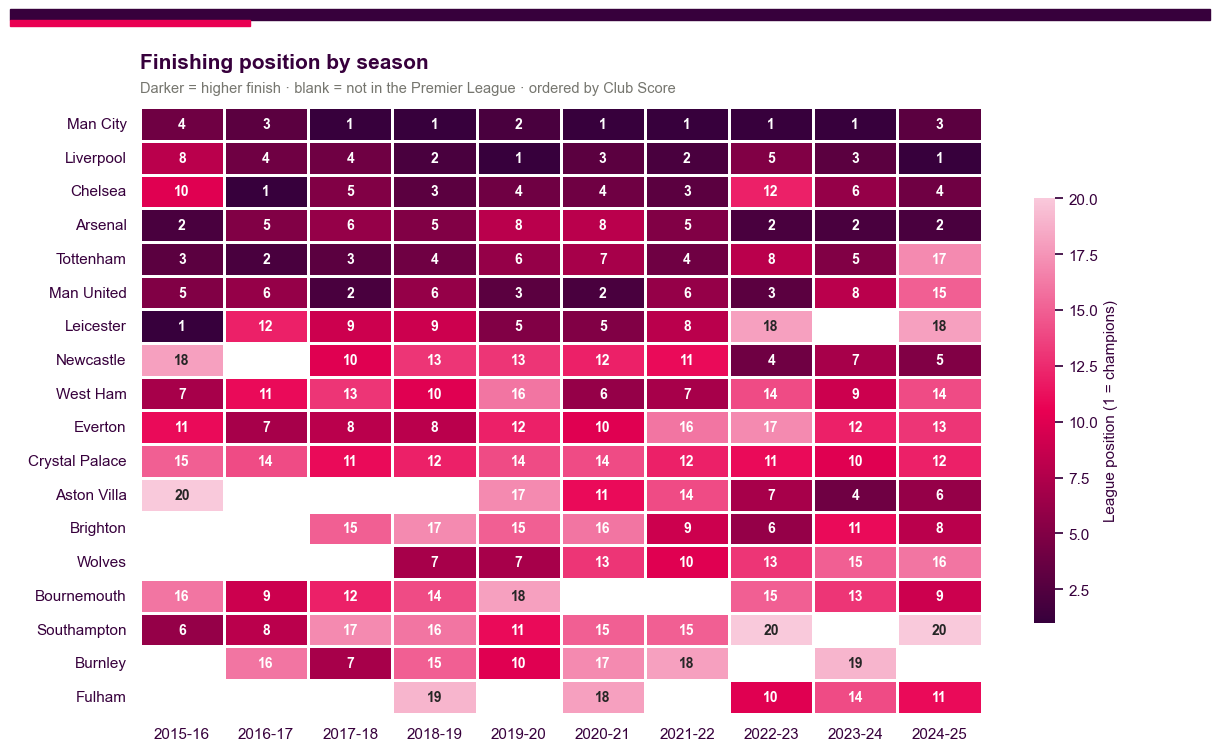

In [14]:
# Heatmap of finishing positions (clubs with at least 5 PL seasons, ordered by Club Score)
heat_clubs = club_summary[club_summary["Seasons"] >= 5]["team"].head(18)
positions = (season_standings[season_standings["team"].isin(heat_clubs)]
             .pivot(index="team", columns="season", values="Position").reindex(heat_clubs))

fig, ax = plt.subplots(figsize=(12, 7.5))
heat_cmap = LinearSegmentedColormap.from_list("pl_pos", [PL["purple"], PL["pink"], "#F9C9DB"])   # 1st → 20th
sns.heatmap(positions, annot=True, fmt=".0f", cmap=heat_cmap, vmin=1, vmax=20, linewidths=2,
            linecolor="white", cbar_kws={"label": "League position (1 = champions)", "shrink": 0.7},
            annot_kws={"fontweight": "bold", "fontsize": 10}, ax=ax)
ax.set_facecolor("white")                          # blank cells = not in the Premier League that season
ax.grid(False)
ax.set(xlabel="", ylabel="")
ax.tick_params(axis="x", rotation=0)
pl_mpl_title(ax, "Finishing position by season",
             "Darker = higher finish · blank = not in the Premier League · ordered by Club Score")
show_mpl(fig)

### 2.4 · Interactive dashboards

**Dashboard A: club trends.** Use the **dropdown** (top right) to switch metric. Use **Select all / Deselect all / Big Six** (top left) or click club names in the legend to choose which clubs are shown, and drag the **range slider** under the chart to zoom into seasons.

**Dashboard B: league table by season.** Drag the **season slider** to see any final table. Green marks the Champions League places and magenta marks relegation.

In [15]:
# ── Dashboard A: one trace per club; the dropdown swaps the y-values of every trace at once ──
metric_options = {"Points": "Points", "Points per match": "Points_per_match",
                  "League position": "Position", "Goal difference": "GD"}
teams_by_score = club_summary["team"].tolist()                      # legend order = Club Score order
per_team = {t: season_standings[season_standings["team"] == t].set_index("season").reindex(SEASON_LABELS)
            for t in teams_by_score}                                 # reindex → gaps for relegated seasons

fig_clubs = go.Figure()
for team in teams_by_score:
    d = per_team[team]
    fig_clubs.add_trace(go.Scatter(
        x=SEASON_LABELS, y=d["Points"], name=team, mode="lines+markers",
        line=dict(color=club_color(team), width=3), marker=dict(size=8),
        visible=True if team in BIG_SIX else "legendonly",
        customdata=d[["Position", "W", "D", "L", "GD"]].to_numpy(),
        hovertemplate="<b>%{fullData.name}</b> · %{x}<br>Value: %{y}<br>Finished: %{customdata[0]}"
                      "<br>W-D-L: %{customdata[1]}-%{customdata[2]}-%{customdata[3]} · GD %{customdata[4]}<extra></extra>",
    ))

def metric_range(col):
    """Fixed y-axis range for a metric: low → high (bigger is better), except position where 1st sits on top."""
    if col == "Position":
        return [20.5, 0.5]
    lo, hi = season_standings[col].min(), season_standings[col].max()
    pad = (hi - lo) * 0.05
    return [lo - pad, hi + pad]


# Metric dropdown: swaps every trace's y-values and sets an explicit, non-reversed range
# (an explicit range avoids Plotly keeping the reversed axis from "League position").
metric_buttons = [
    dict(label=label, method="update",
         args=[{"y": [per_team[t][col].to_numpy() for t in teams_by_score]},
               {"yaxis.title.text": label, "yaxis.autorange": False, "yaxis.range": metric_range(col)}])
    for label, col in metric_options.items()
]
# Club selection buttons: show every club, hide every club, or reset to the Big Six
n_clubs = len(teams_by_score)
club_buttons = [
    dict(label="Select all", method="restyle", args=[{"visible": [True] * n_clubs}]),
    dict(label="Deselect all", method="restyle", args=[{"visible": ["legendonly"] * n_clubs}]),
    dict(label="Big Six", method="restyle",
         args=[{"visible": [True if t in BIG_SIX else "legendonly" for t in teams_by_score]}]),
]
menu_style = dict(bgcolor=PL["light"], bordercolor=PL["purple"], font=dict(color=PL["purple"]))
fig_clubs.update_layout(
    title=pl_title("Club performance by season", "Dropdown = metric · buttons / legend = clubs · slider = seasons"),
    updatemenus=[
        dict(buttons=metric_buttons, direction="down", x=1, xanchor="right", y=1.17, yanchor="top", **menu_style),
        dict(buttons=club_buttons, type="buttons", direction="right", showactive=False,
             x=0, xanchor="left", y=1.08, yanchor="bottom", **menu_style),
    ],
    legend=dict(orientation="v", x=1.02, y=1, yanchor="top", title=dict(text="<b>Club</b>")),
    xaxis=dict(title="Season", rangeslider=dict(visible=True, bgcolor=PL["light"], thickness=0.08)),
    yaxis=dict(title="Points", autorange=False, range=metric_range("Points")),
    height=700, margin=dict(t=150),
)
fig_clubs.show()

In [16]:
# ── Dashboard B: one bar trace per season; the slider shows one trace at a time ──
fig_table = go.Figure()
for season in SEASON_LABELS:
    t = season_standings[season_standings["season"] == season].sort_values("Position")
    bar_colors = [club_color(c) for c in t["team"]]
    fig_table.add_trace(go.Bar(
        x=t["Points"], y=t["Position"], orientation="h", name=season, visible=(season == SEASON_LABELS[-1]),
        marker=dict(color=bar_colors, line=dict(color="white", width=1)),
        text=[f"<b>{c}</b>  {p} pts" for c, p in zip(t["team"], t["Points"])],
        textposition="inside", insidetextanchor="start", textfont=dict(color=[text_on(c) for c in bar_colors]),
        customdata=t[["W", "D", "L", "GD"]].to_numpy(),
        hovertemplate="%{text}<br>W-D-L: %{customdata[0]}-%{customdata[1]}-%{customdata[2]} · GD %{customdata[3]}<extra></extra>",
    ))

# Zone bands: Champions League (top 4) and relegation (bottom 3)
fig_table.add_hrect(y0=0.5, y1=4.5, fillcolor=PL["green"], opacity=0.15, line_width=0, layer="below",
                    annotation_text="Champions League", annotation_position="right",
                    annotation_font=dict(color=PL["green_dk"], size=11))
fig_table.add_hrect(y0=17.5, y1=20.5, fillcolor=PL["pink"], opacity=0.12, line_width=0, layer="below",
                    annotation_text="Relegation", annotation_position="right",
                    annotation_font=dict(color=PL["pink"], size=11))

steps = [dict(method="update", label=s,
              args=[{"visible": [s == other for other in SEASON_LABELS]},
                    {"title.text": pl_title(f"Final Premier League table · {s}", "Drag the slider to change season")}])
         for s in SEASON_LABELS]
fig_table.update_layout(
    title=pl_title(f"Final Premier League table · {SEASON_LABELS[-1]}", "Drag the slider to change season"),
    sliders=[dict(active=len(SEASON_LABELS) - 1, steps=steps, pad=dict(t=50),
                  currentvalue=dict(prefix="Season: ", font=dict(color=PL["purple"], size=15)),
                  bgcolor=PL["light"], activebgcolor=PL["pink"], bordercolor=PL["purple"])],
    yaxis=dict(autorange="reversed", tickmode="array", tickvals=list(range(1, 21)), title="Position"),
    xaxis=dict(title="Points", range=[0, season_standings["Points"].max() * 1.12]),
    showlegend=False, height=760, bargap=0.18, margin=dict(r=140),
)
fig_table.show()

### 2.5 · Sensitivity check and result

A "best club" claim is only robust if it holds up when the weights change. The Club Score is recomputed under three very different weightings.

In [17]:
weight_schemes = {
    "Documented weights": score_weights,
    "Equal weights": {col: 1 / len(score_weights) for col in score_weights},
    "Per-match form only": {"Avg_points_per_match": 0.5, "Goal_difference_per_match": 0.3, "Win_rate": 0.2},
    "Silverware only": {"Titles": 0.6, "Top4_finishes": 0.4},
}
sensitivity = []
for scheme, weights in weight_schemes.items():
    ranked = club_summary.assign(score=compute_club_score(club_summary, weights)).sort_values("score", ascending=False)
    sensitivity.append({"Weighting": scheme, "1st": ranked["team"].iloc[0], "2nd": ranked["team"].iloc[1],
                        "3rd": ranked["team"].iloc[2], "Winner's score": ranked["score"].iloc[0]})
sensitivity = pd.DataFrame(sensitivity)
display(pl_table(sensitivity, precision=1, highlight_first=False))

# ── Result ──
best, second = club_summary.iloc[0], club_summary.iloc[1]
wins = int((sensitivity["1st"] == best["team"]).sum())
q1_detail = (f"Club Score <b>{best['Club_score']:.1f}</b>, {best['Club_score'] - second['Club_score']:.1f} clear of "
             f"{second['team']}. {best['Titles']} titles in 10 seasons, {best['Top4_finishes']}/10 top-four finishes, "
             f"{best['Avg_points_per_match']:.2f} points per match and {best['Goal_difference_per_match']:+.2f} goal difference "
             f"per match. Ranked 1st under <b>{wins} of {len(sensitivity)}</b> weightings.")
FINAL_ANSWERS["Q1"] = ("Q1 · Best club, 2015/16–2024/25", f"🏆 {best['team']}", q1_detail)
result_card(*FINAL_ANSWERS["Q1"])

Weighting,1st,2nd,3rd,Winner's score
Documented weights,Man City,Liverpool,Chelsea,100.0
Equal weights,Man City,Liverpool,Chelsea,100.0
Per-match form only,Man City,Liverpool,Arsenal,100.0
Silverware only,Man City,Liverpool,Chelsea,100.0


In [18]:
# Key takeaways, written from the results above
others = club_summary.iloc[1:]
lead_points = int(best["Total_points"] - others["Total_points"].max())
chasers = club_summary.iloc[2:6]
chaser_spread = chasers["Club_score"].max() - chasers["Club_score"].min()
third_places = list(dict.fromkeys(sensitivity["3rd"]))
closest = champions.nsmallest(2, "Margin (pts)")
lowest_champion = champions.loc[champions["Points"].idxmin()]
gap = best["Club_score"] - second["Club_score"]

takeaways(
    f"**{best['team']} are the {'clear' if gap >= 10 else 'narrow'} answer.** They won {best['Titles']} titles in "
    f"{best['Seasons']} seasons, finished in the top four {best['Top4_finishes']} times, and collected "
    f"{int(best['Total_points']):,} points, {lead_points} more than any other club. "
    f"They rank 1st under {wins} of {len(sensitivity)} weightings.",
    f"**{second['team']} are second** (Club Score {second['Club_score']:.1f}), with {second['Titles']} titles and "
    f"{second['Top4_finishes']} top-four finishes. {', '.join(chasers['team'])} follow within {chaser_spread:.1f} points "
    f"of each other" + (f", so 3rd place depends on the weights ({' or '.join(third_places)})." if len(third_places) > 1 else "."),
    "**The tightest title races:** " + "; ".join(
        f"{r['Champion']} beat {r['Runner-up']} by {r['Margin (pts)']} point{'s' if r['Margin (pts)'] != 1 else ''} in {r['Season']}"
        for _, r in closest.iterrows())
    + f". The lowest winning total was {lowest_champion['Champion']}'s {lowest_champion['Points']} points in {lowest_champion['Season']}.",
)

**Key takeaways**

* **Man City are the clear answer.** They won 6 titles in 10 seasons, finished in the top four 10 times, and collected 853 points, 52 more than any other club. They rank 1st under 4 of 4 weightings.
* **Liverpool are second** (Club Score 78.8), with 2 titles and 8 top-four finishes. Chelsea, Arsenal, Tottenham, Man United follow within 6.9 points of each other, so 3rd place depends on the weights (Chelsea or Arsenal).
* **The tightest title races:** Man City beat Liverpool by 1 point in 2018-19; Man City beat Liverpool by 1 point in 2021-22. The lowest winning total was Leicester's 81 points in 2015-16.

---
# 3 · Q2: Who are the best players?

No single number captures "best", so two complementary lenses are used:

| Lens | Measures | Strengths | Blind spots |
|---|---|---|---|
| **Career FPL points** (2016/17–2024/25) | All-round output: minutes, goals, assists, clean sheets, saves, bonus | Covers all positions; rewards durability | FPL scoring rules; favours long careers |
| **Attacking Score** (per player-season) | Goals, xG, assists and xA **per 90**, plus a small volume term | Rewards elite attacking peaks; xG separates skill from luck | Ignores defending and goalkeeping |

**Attacking Score** = 25% goals/90 + 25% xG/90 + 15% assists/90 + 20% xA/90 + 15% total goals. Each term is a z-score, calculated over outfield players with **at least 900 minutes** (10 full matches).

### 3.1 · Career FPL leaderboard

In [19]:
fpl_top_players = pd.DataFrame()
if not fpl_players.empty:
    by_time = fpl_players.sort_values("season_start_year")              # so "last" = most recent club
    fpl_top_players = (
        by_time.groupby("player", as_index=False)
        .agg(Position=("position", lambda s: s.mode().iat[0]), Club=("team", "last"),
             Seasons=("season", "nunique"), FPL_points=("total_points", "sum"), Minutes=("minutes", "sum"),
             Goals=("goals_scored", "sum"), Assists=("assists", "sum"), Avg_price=("now_cost", "mean"))
    )
    fpl_top_players["Points_per_90"] = np.where(fpl_top_players["Minutes"] > 0,
                                                fpl_top_players["FPL_points"] / fpl_top_players["Minutes"] * 90, np.nan)
    fpl_top_players = fpl_top_players.sort_values("FPL_points", ascending=False).reset_index(drop=True)
    display(pl_table(fpl_top_players.head(15).rename(columns={"FPL_points": "FPL points", "Avg_price": "Avg £m",
                                                              "Points_per_90": "Pts / 90"}),
                     precision=1))

player,Position,Club,Seasons,FPL points,Minutes,Goals,Assists,Avg £m,Pts / 90
Mohamed Salah,MID,Liverpool,8,"2,085","24,068",184,97,12.8,7.8
Harry Kane,FWD,Tottenham,8,"1,456","20,328",163,51,12.1,6.4
Kevin De Bruyne,MID,Man City,9,"1,450","19,225",65,122,10.8,6.8
Raheem Sterling,MID,Arsenal,9,"1,383","19,517",99,82,9.4,6.4
Trent Alexander-Arnold,DEF,Liverpool,9,"1,280","20,692",18,73,6.9,5.6
Jamie Vardy,FWD,Leicester,8,"1,258","21,112",116,49,9.1,5.4
Andrew Robertson,DEF,Liverpool,9,"1,213","23,671",11,61,6.3,4.6
Jordan Pickford,GK,Everton,9,"1,190","28,932",0,2,4.8,3.7
Heung-Min Son,MID,Tottenham,6,"1,166","14,994",89,59,9.1,7.0
Marcus Rashford,MID,Aston Villa,9,"1,130","19,186",84,50,7.9,5.3


**Interactive leaderboard.** Use the buttons to filter by position. Bars are coloured by position, using the same colours as FPL.

In [20]:
if not fpl_top_players.empty:
    TOP_N = 15
    filters = ["All"] + POS_ORDER
    fig_lb = go.Figure()
    ticktexts = {}
    for f in filters:
        d = (fpl_top_players if f == "All" else fpl_top_players[fpl_top_players["Position"] == f]).head(TOP_N)
        ticktexts[f] = d["player"].tolist()
        # y = rank (1…15) rather than the name, so each filter keeps its own ordering on a shared axis
        fig_lb.add_trace(go.Bar(
            x=d["FPL_points"], y=np.arange(1, len(d) + 1), orientation="h", visible=(f == "All"), name=f,
            marker=dict(color=[POS_COLORS[p] for p in d["Position"]]),
            text=d["FPL_points"].astype(int), textposition="outside", textfont=dict(color=PL["purple"]),
            customdata=d[["player", "Club", "Seasons", "Goals", "Assists", "Points_per_90"]].to_numpy(),
            hovertemplate="<b>%{customdata[0]}</b> (%{customdata[1]})<br>FPL points: %{x}<br>Seasons: %{customdata[2]}"
                          "<br>Goals %{customdata[3]} · Assists %{customdata[4]}<br>Pts/90: %{customdata[5]:.2f}<extra></extra>",
        ))
    buttons = [dict(label=f, method="update",
                    args=[{"visible": [f == g for g in filters]},
                          {"yaxis.ticktext": ticktexts[f], "yaxis.tickvals": list(range(1, len(ticktexts[f]) + 1))}])
               for f in filters]
    fig_lb.update_layout(
        title=pl_title(f"Top {TOP_N} career FPL points, 2016/17–2024/25",
                       "Buttons filter by position · colour: GK violet · DEF green · MID cyan · FWD magenta"),
        updatemenus=[dict(type="buttons", direction="right", buttons=buttons, x=0, xanchor="left", y=1.1,
                          yanchor="bottom", bgcolor=PL["light"], bordercolor=PL["purple"],
                          font=dict(color=PL["purple"]), showactive=True)],
        yaxis=dict(autorange="reversed", tickmode="array", tickvals=list(range(1, TOP_N + 1)),
                   ticktext=ticktexts["All"], showgrid=False),
        xaxis=dict(title="Total FPL points", gridcolor=PL["grid"], showgrid=True),
        showlegend=False, height=640, margin=dict(t=150, l=190),
    )
    fig_lb.show()

### 3.2 · Attacking Score: best individual attacking seasons

player,season,team,position,goals,xG,assists,xA,minutes,Attacking Score
Erling Haaland,2022/23,Manchester City,FWD,36,32.76,8,5.85,"2,803",4.54
Mohamed Salah,2024/25,Liverpool,FWD,29,27.71,18,15.86,"3,392",4.07
Mohamed Salah,2017/18,Liverpool,FWD,32,25.14,10,8.34,"2,954",3.90
Erling Haaland,2023/24,Manchester City,FWD,27,31.65,5,4.75,"2,581",3.81
Sergio Agüero,2017/18,Manchester City,FWD,21,18.57,6,6.53,"1,985",3.64
Mohamed Salah,2021/22,Liverpool,FWD,23,24.36,13,9.79,"2,757",3.61
Harry Kane,2016/17,Tottenham,FWD,29,19.82,7,5.55,"2,556",3.54
Cole Palmer,2023/24,"Chelsea,Manchester City",FWD,22,17.83,11,11.87,"2,640",3.40
Mohamed Salah,2023/24,Liverpool,FWD,18,21.94,10,12.33,"2,556",3.38
Sergio Agüero,2019/20,Manchester City,FWD,16,15.56,3,2.92,"1,462",3.30


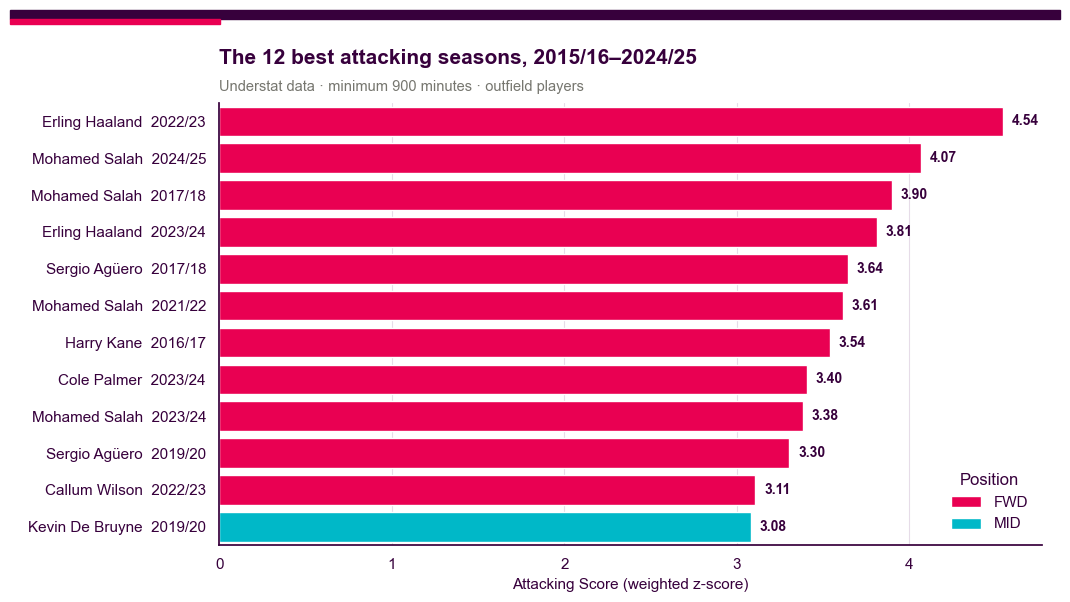

In [21]:
attack_pool = pd.DataFrame()
if not understat_players.empty:
    # Outfield players with ≥900 minutes; goalkeepers are excluded because they would distort the attacking z-scores.
    attack_pool = understat_players[(understat_players["minutes"] >= 900)
                                    & (understat_players["position"] != "GK")].copy()

    def zscore(s):
        return (s - s.mean()) / (s.std(ddof=0) or 1.0)

    attack_weights = {"goals_per90": 0.25, "xG_per90": 0.25, "assists_per90": 0.15, "xA_per90": 0.20, "goals": 0.15}
    attack_pool["Attacking_score"] = sum(w * zscore(attack_pool[c]) for c, w in attack_weights.items())
    attack_pool = attack_pool.sort_values("Attacking_score", ascending=False).reset_index(drop=True)

    display(pl_table(attack_pool[["player", "season", "team", "position", "goals", "xG", "assists", "xA",
                                  "minutes", "Attacking_score"]].head(12)
                     .rename(columns={"Attacking_score": "Attacking Score"})))

    # EDA: top 12 attacking seasons, coloured by position
    top12 = attack_pool.head(12).assign(label=lambda d: d["player"] + "  " + d["season"].astype(str))
    fig, ax = plt.subplots(figsize=(10.5, 6))
    sns.barplot(data=top12, y="label", x="Attacking_score", hue="position", palette=POS_COLORS, dodge=False, saturation=1, ax=ax)
    for i, v in enumerate(top12["Attacking_score"]):
        ax.text(v + 0.05, i, f"{v:.2f}", va="center", fontweight="bold", fontsize=10)
    ax.set(xlabel="Attacking Score (weighted z-score)", ylabel="")
    ax.grid(axis="y", visible=False)
    ax.legend(title="Position", loc="lower right")
    pl_mpl_title(ax, "The 12 best attacking seasons, 2015/16–2024/25", "Understat data · minimum 900 minutes · outfield players")
    show_mpl(fig)

**Interactive explorer: xG vs actual goals.** Press ▶ to play through the seasons (each season holds for 2 seconds) or drag the **season slider**. Each bubble is a player-season, sized by minutes. Players **above the dashed line** scored more than their chances were worth (clinical finishing or luck), and players **below** it under-performed their xG. The top three attacking seasons in each year are labelled. Click a position in the legend to hide it.

In [22]:
if not attack_pool.empty:
    anim = attack_pool.sort_values(["year", "Attacking_score"], ascending=[True, False]).copy()
    # Label only the top 3 attacking seasons in each year to keep the chart readable
    anim["label"] = np.where(anim.groupby("year").cumcount() < 3, anim["player"], "")
    axis_max = float(max(anim["xG"].max(), anim["goals"].max())) + 3

    fig_attack = px.scatter(
        anim, x="xG", y="goals", size="minutes", color="position", text="label", hover_name="player",
        animation_frame="season", color_discrete_map=POS_COLORS, category_orders={"position": ["DEF", "MID", "FWD", "SUB"]},
        hover_data={"team": True, "assists": True, "xA": ":.1f", "minutes": True, "Attacking_score": ":.2f",
                    "label": False, "season": False},
        range_x=[-1, axis_max], range_y=[-1, axis_max], size_max=26,
        labels={"xG": "Expected goals (xG)", "goals": "Actual goals", "position": "Position"},
    )
    fig_attack.update_traces(textposition="top center", textfont=dict(size=11, color=PL["purple"]))
    fig_attack.add_shape(type="line", x0=0, y0=0, x1=axis_max, y1=axis_max, line=dict(dash="dash", color=PL["grey"]))
    fig_attack.add_annotation(x=axis_max * 0.22, y=axis_max * 0.85, text="Above the line =<br>outscoring xG",
                              showarrow=False, font=dict(color=PL["grey"], size=11))
    fig_attack.update_layout(title=pl_title("Expected vs actual goals by season", "Press ▶ or drag the slider · bubble size = minutes"),
                             height=680)
    # Animation timing: a quick 0.4 s transition, then hold each season on screen for 2 s.
    TRANSITION_MS, HOLD_MS = 400, 2000
    play_args = fig_attack.layout.updatemenus[0].buttons[0].args[1]
    play_args["frame"]["duration"] = TRANSITION_MS + HOLD_MS        # frame duration includes the transition
    play_args["transition"]["duration"] = TRANSITION_MS
    fig_attack.layout.sliders[0].update(currentvalue=dict(prefix="Season: ", font=dict(color=PL["purple"], size=15)),
                                        activebgcolor=PL["pink"], bgcolor=PL["light"],
                                        transition=dict(duration=TRANSITION_MS))
    fig_attack.show()

### 3.3 · Result

In [23]:
if not fpl_top_players.empty:
    # Best player at each position by career FPL points: a clear position-by-position answer
    best_by_pos = (fpl_top_players.groupby("Position", group_keys=False)
                   .apply(lambda g: g.head(3)).assign(Rank=lambda d: d.groupby("Position").cumcount() + 1))
    best_by_pos = best_by_pos.set_index("Position").loc[POS_ORDER].reset_index()
    display(pl_table(best_by_pos[["Position", "Rank", "player", "Club", "Seasons", "FPL_points", "Points_per_90"]]
                     .rename(columns={"player": "Player", "FPL_points": "FPL points", "Points_per_90": "Pts / 90"}),
                     precision=2, highlight_first=False))

    top = fpl_top_players.iloc[0]
    runner = fpl_top_players.iloc[1]
    regulars_10k = fpl_top_players[fpl_top_players["Minutes"] >= 10_000].sort_values("Points_per_90", ascending=False)
    efficient = regulars_10k.iloc[0]
    next_best = regulars_10k[regulars_10k["player"] != top["player"]].iloc[0]
    peak = attack_pool.iloc[0] if not attack_pool.empty else None
    q2_detail = (f"<b>{int(top['FPL_points']):,}</b> career FPL points, {int(top['FPL_points'] - runner['FPL_points']):,} more than "
                 f"{runner['player']} · {int(top['Goals'])} goals and {int(top['Assists'])} assists · {top['Points_per_90']:.2f} pts/90."
                 + (f"<br>Also the most efficient player with ≥10,000 minutes; next best: <b>{next_best['player']}</b> "
                   f"({next_best['Points_per_90']:.2f} pts/90)" if efficient["player"] == top["player"] else
                   f"<br>Most efficient (≥10,000 min): <b>{efficient['player']}</b> ({efficient['Points_per_90']:.2f} pts/90)"))
    if peak is not None:
        q2_detail += (f"<br>Best single attacking season: <b>{peak['player']} {peak['season']}</b> "
                      f"({int(peak['goals'])} goals from {peak['xG']:.1f} xG, Attacking Score {peak['Attacking_score']:.2f})")
    FINAL_ANSWERS["Q2"] = ("Q2 · Best player, 2016/17–2024/25", f"⭐ {top['player']}", q2_detail)
    result_card(*FINAL_ANSWERS["Q2"])

Position,Rank,Player,Club,Seasons,FPL points,Pts / 90
GK,1,Jordan Pickford,Everton,9,"1,190",3.70
GK,2,Ederson Santana de Moraes,Man City,8,"1,119",4.11
GK,3,Alisson Ramses Becker,Liverpool,7,995,4.36
DEF,1,Trent Alexander-Arnold,Liverpool,9,"1,280",5.57
DEF,2,Andrew Robertson,Liverpool,9,"1,213",4.61
DEF,3,Virgil van Dijk,Liverpool,9,"1,124",4.27
MID,1,Mohamed Salah,Liverpool,8,"2,085",7.80
MID,2,Kevin De Bruyne,Man City,9,"1,450",6.79
MID,3,Raheem Sterling,Arsenal,9,"1,383",6.38
FWD,1,Harry Kane,Tottenham,8,"1,456",6.45


In [24]:
# Key takeaways, written from the results above
share_more = top["FPL_points"] / runner["FPL_points"] - 1
top_in_best9 = int((attack_pool.head(9)["player"] == top["player"]).sum()) if not attack_pool.empty else 0
best12 = attack_pool.head(12)
mid_seasons = best12[best12["position"] == "MID"]
position_leaders = best_by_pos[best_by_pos["Rank"] == 1]
defender_clubs = best_by_pos[best_by_pos["Position"] == "DEF"]["Club"].value_counts()

takeaways(
    f"**{top['player']} is the standout player:** {int(top['FPL_points']):,} FPL points, {share_more:.0%} more than "
    f"{runner['player']} ({int(runner['FPL_points']):,})"
    + (f", and the best rate of any player with 10,000+ minutes ({top['Points_per_90']:.2f} points per 90)" if efficient["player"] == top["player"] else "")
    + (f". {top['player']} also has {top_in_best9} of the top nine attacking seasons." if top_in_best9 else "."),
    (f"**{peak['player']}'s {peak['season']} ({int(peak['goals'])} goals) is the best single attacking season.** "
     f"{int((best12['position'] == 'FWD').sum())} of the top 12 attacking seasons are by forwards"
     + (": the midfield exception" + ("s are " if len(mid_seasons) > 1 else " is ")
        + ", ".join(f"{r.player} {r.season}" for r in mid_seasons.itertuples()) if len(mid_seasons) else "") + ".") if peak is not None else None,
    "**Best by position:** " + " · ".join(f"{r.Position} {r.player}" for r in position_leaders.itertuples())
    + (f". {defender_clubs.index[0]} supply all three of the highest-scoring defenders." if defender_clubs.iloc[0] == 3
       else f". {defender_clubs.index[0]} supply {defender_clubs.iloc[0]} of the three highest-scoring defenders."),
)

**Key takeaways**

* **Mohamed Salah is the standout player:** 2,085 FPL points, 43% more than Harry Kane (1,456), and the best rate of any player with 10,000+ minutes (7.80 points per 90). Mohamed Salah also has 4 of the top nine attacking seasons.
* **Erling Haaland's 2022/23 (36 goals) is the best single attacking season.** 11 of the top 12 attacking seasons are by forwards: the midfield exception is Kevin De Bruyne 2019/20.
* **Best by position:** GK Jordan Pickford · DEF Trent Alexander-Arnold · MID Mohamed Salah · FWD Harry Kane. Liverpool supply all three of the highest-scoring defenders.

---
# 4 · Q3: What is the best starting XI? *(Experiment 1)*

**Definition of "best".** The best XI is the eleven players with the highest **predicted FPL points for next season** (2025/26), arranged in a legal formation: 1 GK, 3–5 DEF, 2–5 MID and 1–3 FWD. There is no budget cap, so this is a "dream team", not a squad you could afford in FPL.

**Pipeline**

1. **Lag the features.** Each row pairs a player's statistics from season *t − 1* (and *t − 2*) with their season *t* points, so the model never sees the season it is predicting.
2. **Train and test across time.** Train on target seasons 2017/18–2022/23 and test on 2023/24–2024/25. Compare against the naive baseline "same points as last season".
3. **Refit and project.** Refit on all seasons, then predict 2025/26 from the 2023/24 and 2024/25 statistics, **only for players in the 2025/26 Gameweek 1 squad list and at their GW1 club** (transfer-aware, §1.2b).
4. **Optimise.** Try every legal formation and keep the one with the highest total predicted points.

**Model choice.** Next-season points are very noisy. A player who loses their place or gets injured scores close to zero, and one big season is rarely repeated. The model is therefore a **gradient-boosted tree ensemble trained with absolute-error loss**: it targets the *median* outcome rather than the mean, so a handful of extreme seasons do not drag it around.

### 4.1 · Build lagged (previous-season) features

| Feature group | Features | Why |
|---|---|---|
| Last season (`prev_*`) | Points, minutes, goals, assists, clean sheets, bonus, ICT, xG/xA, price, ownership, position | The player's most recent level |
| Two seasons ago (`prev2_*`) | Points and minutes | Separates a one-off season from a sustained level |
| Rate | Points per 90 minutes last season | Spots good players who played little |
| Context | Club's points per match last season, number of earlier FPL seasons | Players at strong clubs score more, and experience adds stability |
| Pre-season (GW1) | New club's points per match last season, changed-club flag, FPL starting price | Captures summer transfers, and FPL's own pre-season valuation of each player |

Seasons are linked by FPL's **stable player ID**, so a name change (e.g. "Daniel Muñoz" → "Daniel Muñoz Mejía") or a position change (Bowen MID → FWD) no longer breaks a player's history.

In [25]:
panel_parts = build_player_panel(fpl_players, season_standings, gw1_squads)     # pl_analytics/features.py
player_lagged = panel_parts["player_lagged"]          # training rows (season t-1 features → season t points)
projection_all = panel_parts["projection_all"]        # every 2024-25 player projected one season ahead
projection_rows = panel_parts["projection_rows"]      # ...only those in the 2025-26 GW1 squad list (transfer-aware)
latest_year = panel_parts["latest_year"]

movers = projection_rows[projection_rows["changed_club"] == 1]
print(f"{season_label(latest_year + 1)} projections: {len(projection_rows):,} players in the GW1 squad list "
      f"({len(projection_all) - len(projection_rows):,} of last season's players dropped · {len(movers):,} changed club)")
print(f"✓ Lagged examples: {len(player_lagged):,} player-season pairs · target seasons: "
      f"{player_lagged['season'].min()} → {player_lagged['season'].max()}")
display(pl_table(player_lagged[["player", "position", "season", "prev_total_points", "total_points",
                                "prev_now_cost", "now_cost"]].sort_values("total_points", ascending=False).head(5)
                 .rename(columns={"prev_total_points": "Points (t−1)", "total_points": "Points (t)",
                                  "prev_now_cost": "£m (t−1)", "now_cost": "£m (t)"}), precision=1))

2025-26 projections: 512 players in the GW1 squad list (272 of last season's players dropped · 45 changed club)
✓ Lagged examples: 3,713 player-season pairs · target seasons: 2017-18 → 2024-25


player,position,season,Points (t−1),Points (t),£m (t−1),£m (t)
Mohamed Salah,MID,2024-25,211.0,344.0,13.4,13.6
Mohamed Salah,MID,2021-22,231.0,265.0,12.9,13.1
Harry Kane,FWD,2022-23,192.0,263.0,12.5,11.5
Mohamed Salah,MID,2018-19,303.0,259.0,10.6,13.2
Heung-Min Son,MID,2021-22,228.0,258.0,9.6,11.2


### 4.2 · Shared model pipeline

The pipelines live in `pl_analytics/models.py`. Experiments 1 and 2 share the same preprocessing: median imputation and scaling for numbers, and one-hot encoding for position. Only the estimator at the end differs. Because the preprocessing sits inside the pipeline, the imputer and scaler are fitted on **training data only**, which avoids leakage from the test seasons.

In [26]:
HOLDOUT_FROM = 2023                       # test on target seasons 2023-24 and 2024-25
# Older FPL exports lack xG/starts columns, so they are entirely empty in the early training seasons.
# The imputer drops such all-empty columns automatically; silence its (expected) warning.
warnings.filterwarnings("ignore", message="Skipping features without any observed values")


def latest_season_as_features():
    """Transfer-aware projection rows for the next season, with last season's stats in the plain columns."""
    return as_projection_table(projection_rows), season_label(latest_year + 1)


print(f"Points model: {len(points_feature_cols)} features · price model: {len(model_feature_cols)} features · "
      f"holdout = target seasons ≥ {season_label(HOLDOUT_FROM)}")

Points model: 28 features · price model: 20 features · holdout = target seasons ≥ 2023-24


### 4.3 · Train and evaluate the points model

**Metrics.** MAE is the average error in FPL points. RMSE punishes large misses more heavily. R² is the share of the variance explained (1 = perfect, 0 = no better than predicting the average).

In [27]:
points_holdout_model = None
if not player_lagged.empty:
    player_train = player_lagged[player_lagged["target_season_year"] < HOLDOUT_FROM]
    player_test = player_lagged[player_lagged["target_season_year"] >= HOLDOUT_FROM]

    points_holdout_model = make_points_pipeline()
    points_holdout_model.fit(player_train[points_feature_cols], player_train["total_points"])
    test_points_pred = np.clip(points_holdout_model.predict(player_test[points_feature_cols]), 0, None)  # no negative totals

    points_metrics = pd.DataFrame([
        regression_metrics("Gradient boosting (median loss)", player_test["total_points"], test_points_pred),
        regression_metrics("Baseline: same as last season", player_test["total_points"], player_test["prev_total_points"]),
    ])
    print(f"Train: {len(player_train):,} rows · Test: {len(player_test):,} rows "
          f"({', '.join(sorted(player_test['season'].unique()))})")
    display(pl_table(points_metrics, precision=3))
    add_experiment_result("1", "Q3 Best XI", "Next-season FPL points", "Gradient boosting (median loss)", "MAE (points)",
                          points_metrics.loc[0, "MAE"], "Same as last season", points_metrics.loc[1, "MAE"], False)

    # Predicted vs actual for the holdout seasons
    fig_points = px.scatter(
        player_test.assign(predicted=test_points_pred), x="total_points", y="predicted", color="position",
        color_discrete_map=POS_COLORS, category_orders={"position": POS_ORDER}, hover_name="player",
        hover_data={"season": True, "team": True, "prev_total_points": True}, opacity=0.75,
        labels={"total_points": "Actual FPL points", "predicted": "Predicted FPL points", "position": "Position"},
    )
    top = float(max(player_test["total_points"].max(), test_points_pred.max()))
    fig_points.add_shape(type="line", x0=0, y0=0, x1=top, y1=top, line=dict(dash="dash", color=PL["grey"]))
    fig_points.update_layout(title=pl_title("Experiment 1: predicted vs actual next-season FPL points",
                                            "Holdout seasons 2023/24–2024/25 · dashed line = perfect prediction"),
                             height=580)
    fig_points.show()

Train: 2,674 rows · Test: 1,039 rows (2023-24, 2024-25)


Model,MAE,RMSE,R²
Gradient boosting (median loss),28.545,41.217,0.387
Baseline: same as last season,29.858,43.756,0.310


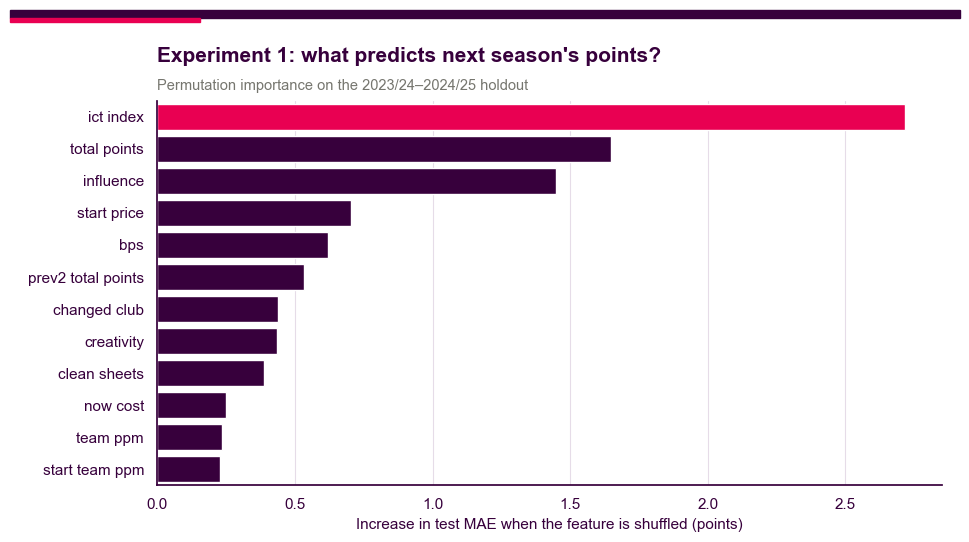

In [28]:
# What drives the prediction? Permutation importance on the holdout seasons: shuffle one feature at a time
# and measure how much the test MAE gets worse. Bigger = the model relies on it more.
if points_holdout_model is not None:
    perm = permutation_importance(points_holdout_model, player_test[points_feature_cols], player_test["total_points"],
                                  scoring="neg_mean_absolute_error", n_repeats=5, random_state=RANDOM_STATE)
    importances = (pd.Series(perm.importances_mean, index=[c.replace("prev_", "").replace("_", " ") for c in points_feature_cols])
                   .sort_values(ascending=False).head(12).rename_axis("feature").reset_index(name="importance"))
    fig, ax = plt.subplots(figsize=(9.5, 5.4))
    sns.barplot(data=importances, y="feature", x="importance", color=PL["purple"], saturation=1, ax=ax)
    ax.patches[0].set_facecolor(PL["pink"])                         # highlight the single strongest driver
    ax.set(xlabel="Increase in test MAE when the feature is shuffled (points)", ylabel="")
    ax.grid(axis="y", visible=False)
    pl_mpl_title(ax, "Experiment 1: what predicts next season's points?", "Permutation importance on the 2023/24–2024/25 holdout")
    show_mpl(fig)

### 4.3b · How sure is each forecast? 80% ranges

One number hides how uncertain a forecast is. Two extra models, trained with **quantile loss**, predict the 10th and 90th percentile of each player's next-season points. Together they give an **80% range**: if the ranges are honest, about 8 in 10 actual totals should land inside them. This is checked on the 2023/24–2024/25 holdout.

In [29]:
range_models = {q: make_points_pipeline(quantile=q).fit(player_train[points_feature_cols], player_train["total_points"])
                for q in (0.1, 0.9)}
test_low = np.clip(range_models[0.1].predict(player_test[points_feature_cols]), 0, None)
test_high = np.maximum(np.clip(range_models[0.9].predict(player_test[points_feature_cols]), 0, None), test_low)  # never cross

holdout_coverage = interval_coverage(player_test["total_points"], test_low, test_high)
coverage_by_pos = (player_test.assign(low=test_low, high=test_high)
                   .groupby("position").apply(lambda g: pd.Series(interval_coverage(g["total_points"], g["low"], g["high"])))
                   .reindex(POS_ORDER).reset_index())
display(pl_table(pd.concat([pd.DataFrame([{"position": "All", **holdout_coverage}]), coverage_by_pos])
                 .rename(columns={"position": "Position", "Coverage": "Share inside the 80% range", "Average width": "Average width (pts)"}),
                 precision=2, highlight_first=False))

Position,Share inside the 80% range,Average width (pts)
All,0.75,74.66
GK,0.83,68.58
DEF,0.75,71.72
MID,0.75,76.88
FWD,0.72,80.30


### 4.4 · Project 2025/26 points and pick the best XI

In [30]:
predicted_points_next = pd.DataFrame()
if points_holdout_model is not None:
    # Refit on every season, then project the season after the last one in the data
    points_final_model = make_points_pipeline()
    points_final_model.fit(player_lagged[points_feature_cols], player_lagged["total_points"])
    latest_players, projection_label = latest_season_as_features()
    latest_players["predicted_next_points"] = np.clip(points_final_model.predict(latest_players[points_feature_cols]), 0, None)
    # 80% range from the two quantile models, refitted on every season like the main model
    for q, col in [(0.1, "points_low"), (0.9, "points_high")]:
        model_q = make_points_pipeline(quantile=q).fit(player_lagged[points_feature_cols], player_lagged["total_points"])
        latest_players[col] = np.clip(model_q.predict(latest_players[points_feature_cols]), 0, None)
    latest_players["points_high"] = np.maximum(latest_players["points_high"], latest_players["points_low"])
    latest_players["points_range"] = (latest_players["points_low"].round().astype(int).astype(str) + "–"
                                      + latest_players["points_high"].round().astype(int).astype(str))
    predicted_points_next = latest_players.sort_values("predicted_next_points", ascending=False)

    print(f"Projected season: {projection_label} (features from {season_label(int(latest_year))} and earlier)")
    display(pl_table(predicted_points_next[["player", "position", "team", "total_points", "now_cost", "predicted_next_points", "points_range"]]
                     .head(10).rename(columns={"total_points": "2024/25 pts", "now_cost": "£m",
                                               "predicted_next_points": f"Predicted {projection_label} pts", "points_range": "80% range"}),
                     precision=1))

    # Range chart: the 20 highest projections, with their 80% ranges as error bars
    top20 = predicted_points_next.head(20).iloc[::-1]
    fig_ranges = go.Figure(go.Scatter(
        x=top20["predicted_next_points"], y=top20["player"], mode="markers",
        marker=dict(size=12, color=[POS_COLORS[p] for p in top20["position"]], line=dict(color="white", width=1)),
        error_x=dict(type="data", symmetric=False, array=top20["points_high"] - top20["predicted_next_points"],
                     arrayminus=top20["predicted_next_points"] - top20["points_low"], color=PL["purple"], thickness=2, width=6),
        customdata=top20[["team", "points_range"]].to_numpy(),
        hovertemplate="<b>%{y}</b> (%{customdata[0]})<br>Predicted %{x:.0f} pts · 80% range %{customdata[1]}<extra></extra>"))
    fig_ranges.update_layout(title=pl_title(f"Top 20 projected players for {projection_label}, with 80% ranges",
                                            "Dot = central forecast · bar = 10th to 90th percentile · colour = position"),
                             xaxis_title="Predicted FPL points", yaxis=dict(showgrid=False), height=640, margin=dict(l=210))
    fig_ranges.show()

Projected season: 2025-26 (features from 2024-25 and earlier)


player,position,team,2024/25 pts,£m,Predicted 2025-26 pts,80% range
Mohamed Salah,MID,Liverpool,344.0,13.6,188.6,88–235
Alexander Isak,FWD,Newcastle,211.0,9.4,181.6,109–227
Cole Palmer,MID,Chelsea,214.0,10.5,181.3,71–244
Bryan Mbeumo,MID,Man United,236.0,8.3,177.0,106–218
Erling Haaland,FWD,Man City,181.0,14.9,170.7,68–217
Jarrod Bowen,MID,West Ham,193.0,7.9,160.9,41–192
Bruno Borges Fernandes,MID,Man United,174.0,8.4,160.0,66–199
Luis Díaz,MID,Liverpool,183.0,7.5,144.8,87–191
Ollie Watkins,FWD,Aston Villa,186.0,9.2,139.8,86–228
Antoine Semenyo,MID,Bournemouth,165.0,5.7,136.0,62–167


In [31]:
best_xi = select_best_xi(predicted_points_next) if not predicted_points_next.empty else pd.DataFrame()
if not best_xi.empty:
    counts = best_xi["position"].value_counts()
    formation = f"{counts.get('DEF', 0)}-{counts.get('MID', 0)}-{counts.get('FWD', 0)}"
    xi_total = best_xi["predicted_next_points"].sum()
    fig_pitch = draw_xi_pitch(best_xi, "predicted_next_points", f"Best predicted XI for {projection_label} · {formation}",
                              f"Number in each circle = predicted FPL points · team total {xi_total:.0f} pts")
    fig_pitch.show()

    display(pl_table(best_xi[["position", "player", "team", "now_cost", "total_points", "predicted_next_points", "points_range"]]
                     .rename(columns={"now_cost": "£m", "total_points": "2024/25 pts", "predicted_next_points": "Predicted pts",
                                      "points_range": "80% range"}),
                     precision=1, highlight_first=False))

    captain = best_xi.sort_values("predicted_next_points", ascending=False).iloc[0]
    FINAL_ANSWERS["Q3"] = (
        f"Q3 · Best XI for {projection_label}",
        f"{formation} · {xi_total:.0f} predicted points",
        f"Captain pick: <b>{captain['player']}</b> ({captain['predicted_next_points']:.0f} pts). "
        f"XI: {', '.join(best_xi['web_name'])}. Team cost £{best_xi['now_cost'].sum():.1f}m (no budget cap applied). "
        f"Model MAE {points_metrics.loc[0, 'MAE']:.1f} pts vs {points_metrics.loc[1, 'MAE']:.1f} for the 'same as last season' baseline.",
    )
    result_card(*FINAL_ANSWERS["Q3"])
else:
    print("Could not build a full XI: a position group is missing from the latest FPL season.")

position,player,team,£m,2024/25 pts,Predicted pts,80% range
GK,Jordan Pickford,Everton,5.2,158.0,128.8,36–145
DEF,Nathan Collins,Brentford,4.6,127.0,109.7,55–132
DEF,William Saliba,Arsenal,6.4,130.0,102.9,34–139
DEF,Murillo Santiago Costa dos Santos,Nott'm Forest,4.7,130.0,101.9,59–135
MID,Mohamed Salah,Liverpool,13.6,344.0,188.6,88–235
MID,Cole Palmer,Chelsea,10.5,214.0,181.3,71–244
MID,Bryan Mbeumo,Man United,8.3,236.0,177.0,106–218
MID,Jarrod Bowen,West Ham,7.9,193.0,160.9,41–192
MID,Bruno Borges Fernandes,Man United,8.4,174.0,160.0,66–199
FWD,Alexander Isak,Newcastle,9.4,211.0,181.6,109–227


### 4.5 · A real FPL squad: £100m, 15 players, a captain every week

The dream XI above ignores FPL's rules. This section builds a squad you could actually enter, using an **integer program** (`pick_fpl_squad` in `pl_analytics/models.py`, solved with SciPy's `milp`):

| FPL rule | Constraint |
|---|---|
| Budget | Total starting price ≤ £100m (prices from the Gameweek 1 list) |
| Squad shape | 2 GK, 5 DEF, 5 MID, 3 FWD |
| Club limit | At most 3 players from any one club |
| Starting XI | 1 GK, 3–5 DEF, 2–5 MID, 1–3 FWD |
| Captain | One starter, whose points count twice |

The solver maximises the XI's predicted points plus the captain's, with a small weight on the bench (substitutes only score when a starter misses a match).

**Captain plan.** The season forecast is spread across the published fixture list. Each starter's weekly expectation is their season forecast ÷ 38, scaled up against weak opponents (by last season's points per match) and at home. The highest expectation each gameweek gets the armband. Only the fixture list is used here; the 2025/26 results are not touched until §7.

In [32]:
fpl_squad = pick_fpl_squad(predicted_points_next, "predicted_next_points", price_col="start_price")
starters = fpl_squad[fpl_squad["starter"]]
squad_captain = starters[starters["captain"]].iloc[0]
squad_counts = starters["position"].value_counts()
squad_formation = f"{squad_counts.get('DEF', 0)}-{squad_counts.get('MID', 0)}-{squad_counts.get('FWD', 0)}"
squad_cost = fpl_squad["start_price"].sum()
squad_xi_points = starters["predicted_next_points"].sum()

# Rule check: every FPL constraint, verified on the chosen squad
checks = {
    "Budget ≤ £100m": squad_cost <= 100,
    "2 GK / 5 DEF / 5 MID / 3 FWD": fpl_squad["position"].value_counts().to_dict() == FPL_SQUAD_SIZE,
    "≤ 3 players per club": fpl_squad["team"].value_counts().max() <= 3,
    "11 starters in a legal formation": len(starters) == 11 and all(
        FPL_XI_LIMITS[p][0] <= squad_counts.get(p, 0) <= FPL_XI_LIMITS[p][1] for p in POS_ORDER),
}
print(" · ".join(f"{'✅' if ok else '❌'} {rule}" for rule, ok in checks.items()))

fig_squad = draw_xi_pitch(starters, "predicted_next_points", f"FPL-legal squad for {projection_label} · {squad_formation}",
                          f"£{squad_cost:.1f}m of £100m · XI predicted {squad_xi_points:.0f} pts · (C) = captain")
fig_squad.show()
display(pl_table(fpl_squad.assign(Role=np.where(fpl_squad["captain"], "Captain", np.where(fpl_squad["starter"], "Starter", "Bench")))
                 [["Role", "position", "player", "team", "start_price", "predicted_next_points", "points_range"]]
                 .rename(columns={"start_price": "£m (GW1)", "predicted_next_points": "Predicted pts", "points_range": "80% range"}),
                 precision=1, highlight_first=False))

✅ Budget ≤ £100m · ✅ 2 GK / 5 DEF / 5 MID / 3 FWD · ✅ ≤ 3 players per club · ✅ 11 starters in a legal formation


Role,position,player,team,£m (GW1),Predicted pts,80% range
Starter,GK,Jordan Pickford,Everton,5.5,128.8,36–145
Starter,DEF,Nathan Collins,Brentford,5.0,109.7,55–132
Starter,DEF,Murillo Santiago Costa dos Santos,Nott'm Forest,5.5,101.9,59–135
Starter,DEF,Marc Guéhi,Crystal Palace,4.5,91.9,37–114
Starter,MID,Cole Palmer,Chelsea,10.5,181.3,71–244
Starter,MID,Bryan Mbeumo,Man United,8.0,177.0,106–218
Starter,MID,Jarrod Bowen,West Ham,8.0,160.9,41–192
Starter,MID,Bruno Borges Fernandes,Man United,9.0,160.0,66–199
Starter,MID,Luis Díaz,Liverpool,8.0,144.8,87–191
Captain,FWD,Alexander Isak,Newcastle,10.5,181.6,109–227


In [33]:
# Weekly captain plan from the published 2025/26 fixture list (fixture columns only, no results)
fixtures_next = load_match_season(FORECAST_SEASON)[["match_date", "HomeTeam", "AwayTeam"]]
club_strength = season_standings[season_standings["season"] == SEASON_LABELS[-1]].set_index("team")["Points_per_match"].to_dict()
plan = captain_plan(starters, fixtures_next, club_strength, "predicted_next_points")

display(pl_table(plan.head(10).assign(home=lambda d: np.where(d["home"], "H", "A"))
                 [["gameweek", "player", "team", "opponent", "home", "expected_points"]]
                 .rename(columns={"gameweek": "GW", "home": "H/A", "expected_points": "Expected pts (1×)"}),
                 precision=1, highlight_first=False))

captaincies = plan["player"].value_counts().rename_axis("player").reset_index(name="gameweeks")
fig_captains = px.bar(captaincies.iloc[::-1], x="gameweeks", y="player", orientation="h", text="gameweeks",
                      color_discrete_sequence=[PL["pink"]], labels={"gameweeks": "Gameweeks as captain", "player": ""})
fig_captains.update_layout(title=pl_title(f"Captain plan: who wears the armband across {len(plan)} gameweeks",
                                          "Picked each week from the starting XI by season forecast × fixture difficulty"),
                           height=380, yaxis=dict(showgrid=False))
fig_captains.show()

FINAL_ANSWERS["Q3 squad"] = (
    f"Q3 · FPL-legal squad for {projection_label}",
    f"{squad_formation} · £{squad_cost:.1f}m · captain {squad_captain['player']}",
    f"XI predicted {squad_xi_points:.0f} points ({squad_xi_points / xi_total:.0%} of the unrestricted dream XI) within FPL's "
    f"£100m budget and 3-per-club rule. Weekly captain plan: {captaincies.iloc[0]['player']} in "
    f"{captaincies.iloc[0]['gameweeks']} of {len(plan)} gameweeks.",
)
result_card(*FINAL_ANSWERS["Q3 squad"])

GW,player,team,opponent,H/A,Expected pts (1×)
1,Jarrod Bowen,West Ham,Sunderland,A,8.0
2,Cole Palmer,Chelsea,West Ham,A,4.7
3,Bryan Mbeumo,Man United,Burnley,H,10.7
4,Jean-Philippe Mateta,Crystal Palace,Sunderland,H,8.1
5,Murillo Santiago Costa dos Santos,Nott'm Forest,Burnley,A,5.0
6,Murillo Santiago Costa dos Santos,Nott'm Forest,Sunderland,H,6.2
7,Bryan Mbeumo,Man United,Sunderland,H,10.7
8,Luis Díaz,Liverpool,Man United,H,4.7
9,Cole Palmer,Chelsea,Sunderland,H,11.0
10,Jordan Pickford,Everton,Sunderland,A,6.4


In [34]:
# Key takeaways, written from the results above
ranked_xi = best_xi.sort_values("predicted_next_points", ascending=False)
movers_in_xi = best_xi[best_xi["changed_club"] == 1]
pm, pb = points_metrics.iloc[0], points_metrics.iloc[1]
top_features = importances["feature"].tolist()
preseason_top7 = [f for f in top_features[:7] if f.replace(" ", "_") in PRESEASON_FEATURES]
coverage = holdout_coverage["Coverage"]
range_verdict = "honest" if abs(coverage - 0.8) <= 0.05 else ("too narrow" if coverage < 0.8 else "too wide")

takeaways(
    f"**The projected XI lines up {formation}.** {ranked_xi.iloc[0]['player']} is the captain pick "
    f"({ranked_xi.iloc[0]['predicted_next_points']:.0f} predicted points, range {ranked_xi.iloc[0]['points_range']}), ahead of "
    f"{ranked_xi.iloc[1]['player']} ({ranked_xi.iloc[1]['predicted_next_points']:.0f}) and "
    f"{ranked_xi.iloc[2]['player']} ({ranked_xi.iloc[2]['predicted_next_points']:.0f})."
    + (" Because the forecast is transfer-aware, " + ", ".join(f"{r.player} ({r.team})" for r in movers_in_xi.itertuples())
       + " " + ("is" if len(movers_in_xi) == 1 else "are") + " projected at the new club." if len(movers_in_xi) else ""),
    f"**The model {'beats' if pm['MAE'] < pb['MAE'] else 'does not beat'} \"same points as last season\"** on the 2023/24–2024/25 "
    f"holdout: MAE {pm['MAE']:.1f} vs {pb['MAE']:.1f}, RMSE {pm['RMSE']:.1f} vs {pb['RMSE']:.1f}, R² {pm['R²']:.2f} vs {pb['R²']:.2f}.",
    f"**Strongest signals:** {', '.join(top_features[:3])}."
    + (f" Pre-season features in the top seven: {', '.join(preseason_top7)}." if preseason_top7 else ""),
    f"**The 80% ranges are {range_verdict}:** {coverage:.0%} of actual holdout totals fell inside them (target 80%), "
    f"with an average width of {holdout_coverage['Average width']:.0f} points. Wide ranges are the honest message: "
    "next-season points depend on injuries, transfers and rotation.",
    f"**The FPL-legal squad** costs £{squad_cost:.1f}m and lines up {squad_formation}. Its XI is predicted to score "
    f"{squad_xi_points:.0f} points, {squad_xi_points / xi_total:.0%} of the unrestricted dream XI, so the budget and "
    f"3-per-club rule cost {xi_total - squad_xi_points:.0f} predicted points.",
)

**Key takeaways**

* **The projected XI lines up 3-5-2.** Mohamed Salah is the captain pick (189 predicted points, range 88–235), ahead of Alexander Isak (182) and Cole Palmer (181). Because the forecast is transfer-aware, Bryan Mbeumo (Man United) is projected at the new club.
* **The model beats "same points as last season"** on the 2023/24–2024/25 holdout: MAE 28.5 vs 29.9, RMSE 41.2 vs 43.8, R² 0.39 vs 0.31.
* **Strongest signals:** ict index, total points, influence. Pre-season features in the top seven: start price, changed club.
* **The 80% ranges are honest:** 75% of actual holdout totals fell inside them (target 80%), with an average width of 75 points. Wide ranges are the honest message: next-season points depend on injuries, transfers and rotation.
* **The FPL-legal squad** costs £100.0m and lines up 3-5-2. Its XI is predicted to score 1571 points, 94% of the unrestricted dream XI, so the budget and 3-per-club rule cost 92 predicted points.

---
# 5 · Q4: What will player prices be next season? *(Experiment 2)*

**Target.** The FPL price (£m) at the end of season *t*, predicted from season *t − 1* statistics, which include the previous price, points, minutes, xG and ownership. This is the **FPL game price**, not a transfer fee.

**Evaluation.** The holdout is target seasons 2023/24–2024/25, as in Experiment 1. The baseline is *"price stays the same"*, which is hard to beat because FPL prices move slowly (usually by £0.1–1.0m a season). Projections are clipped to FPL's realistic range of £3.5m–£15.0m.

### 5.1 · Train and evaluate the price model

In [35]:
price_holdout_model = None
PRICE_FLOOR, PRICE_CAP = 3.5, 15.0
if not player_lagged.empty:
    price_rows = player_lagged.dropna(subset=["now_cost", "prev_now_cost"])
    price_train = price_rows[price_rows["target_season_year"] < HOLDOUT_FROM]
    price_test = price_rows[price_rows["target_season_year"] >= HOLDOUT_FROM]

    price_holdout_model = make_regression_pipeline()
    price_holdout_model.fit(price_train[model_feature_cols], price_train["now_cost"])
    test_price_pred = np.clip(price_holdout_model.predict(price_test[model_feature_cols]), PRICE_FLOOR, PRICE_CAP)

    price_metrics = pd.DataFrame([
        regression_metrics("Random forest", price_test["now_cost"], test_price_pred),
        regression_metrics("Baseline: price unchanged", price_test["now_cost"], price_test["prev_now_cost"]),
    ])
    print(f"Train: {len(price_train):,} rows · Test: {len(price_test):,} rows · errors in £m")
    display(pl_table(price_metrics, precision=3))
    add_experiment_result("2", "Q4 Prices", "Next-season FPL price (£m)", "Random forest regressor", "MAE (£m)",
                          price_metrics.loc[0, "MAE"], "Price unchanged", price_metrics.loc[1, "MAE"], False)

    fig_price_eval = px.scatter(
        price_test.assign(predicted=test_price_pred), x="now_cost", y="predicted", color="position",
        color_discrete_map=POS_COLORS, category_orders={"position": POS_ORDER}, hover_name="player",
        hover_data={"season": True, "team": True, "prev_now_cost": True}, opacity=0.75,
        labels={"now_cost": "Actual price (£m)", "predicted": "Predicted price (£m)", "position": "Position"},
    )
    fig_price_eval.add_shape(type="line", x0=PRICE_FLOOR, y0=PRICE_FLOOR, x1=PRICE_CAP, y1=PRICE_CAP,
                             line=dict(dash="dash", color=PL["grey"]))
    fig_price_eval.update_layout(title=pl_title("Experiment 2: predicted vs actual FPL price",
                                                "Holdout seasons 2023/24–2024/25 · dashed line = perfect prediction"),
                                 height=580)
    fig_price_eval.show()

Train: 2,674 rows · Test: 1,039 rows · errors in £m


Model,MAE,RMSE,R²
Random forest,0.244,0.370,0.899
Baseline: price unchanged,0.314,0.488,0.824


### 5.2 · Project 2025/26 prices

In [36]:
predicted_prices_next = pd.DataFrame()
if price_holdout_model is not None:
    price_final_model = make_regression_pipeline()
    price_final_model.fit(price_rows[model_feature_cols], price_rows["now_cost"])
    latest, projection_label = latest_season_as_features()
    latest["projected_price"] = np.clip(price_final_model.predict(latest[model_feature_cols]), PRICE_FLOOR, PRICE_CAP)
    latest["price_change"] = latest["projected_price"] - latest["now_cost"]
    predicted_prices_next = latest.sort_values("projected_price", ascending=False)

    print(f"Projected FPL prices for {projection_label}: the 15 most expensive players")
    display(pl_table(predicted_prices_next[["player", "position", "team", "total_points", "now_cost", "projected_price", "price_change"]]
                     .head(15).rename(columns={"total_points": "2024/25 pts", "now_cost": "2024/25 £m",
                                               "projected_price": f"{projection_label} £m", "price_change": "Change £m"}),
                     precision=1))

Projected FPL prices for 2025-26: the 15 most expensive players


player,position,team,2024/25 pts,2024/25 £m,2025-26 £m,Change £m
Mohamed Salah,MID,Liverpool,344.0,13.6,13.3,-0.3
Erling Haaland,FWD,Man City,181.0,14.9,11.5,-3.4
Cole Palmer,MID,Chelsea,214.0,10.5,10.7,0.2
Alexander Isak,FWD,Newcastle,211.0,9.4,10.5,1.1
Bukayo Saka,MID,Arsenal,127.0,10.4,9.6,-0.8
Ollie Watkins,FWD,Aston Villa,186.0,9.2,9.3,0.1
Bryan Mbeumo,MID,Man United,236.0,8.3,8.9,0.6
Son Heung-min,MID,Tottenham,129.0,9.7,8.8,-0.9
Phil Foden,MID,Man City,105.0,9.1,8.3,-0.8
Jarrod Bowen,MID,West Ham,193.0,7.9,8.2,0.3


**Projected risers and fallers.** Among regular players (at least 900 minutes in 2024/25), these are the biggest projected price changes. Hover over a bar for details.

In [37]:
if not predicted_prices_next.empty:
    regulars = predicted_prices_next[predicted_prices_next["minutes"] >= 900]
    movers = pd.concat([regulars.nlargest(10, "price_change"), regulars.nsmallest(10, "price_change")])
    movers = movers.sort_values("price_change")
    fig_movers = go.Figure(go.Bar(
        x=movers["price_change"], y=movers["player"] + " (" + movers["team"] + ")", orientation="h",
        marker_color=np.where(movers["price_change"] >= 0, PL["green_dk"], PL["pink"]),
        text=[f"{v:+.1f}" for v in movers["price_change"]], textposition="outside",
        customdata=movers[["now_cost", "projected_price", "total_points"]].to_numpy(),
        hovertemplate="<b>%{y}</b><br>£%{customdata[0]:.1f}m → £%{customdata[1]:.1f}m"
                      "<br>2024/25 points: %{customdata[2]}<extra></extra>",
    ))
    fig_movers.add_vline(x=0, line=dict(color=PL["purple"], width=2))
    fig_movers.update_layout(title=pl_title(f"Projected FPL price movers for {projection_label}",
                                            "Green = projected rise · magenta = projected fall · regulars with ≥900 minutes"),
                             xaxis_title="Projected change (£m)", yaxis=dict(showgrid=False), height=680,
                             margin=dict(l=230), showlegend=False)
    fig_movers.show()

    priciest, riser, faller = predicted_prices_next.iloc[0], regulars.loc[regulars["price_change"].idxmax()], regulars.loc[regulars["price_change"].idxmin()]
    FINAL_ANSWERS["Q4"] = (
        f"Q4 · Projected FPL prices for {projection_label}",
        f"💷 {priciest['player']} £{priciest['projected_price']:.1f}m",
        f"Most expensive projected player. Biggest riser: <b>{riser['player']}</b> £{riser['now_cost']:.1f}m → "
        f"£{riser['projected_price']:.1f}m · biggest faller: <b>{faller['player']}</b> £{faller['now_cost']:.1f}m → "
        f"£{faller['projected_price']:.1f}m. Typical error ±£{price_metrics.loc[0, 'MAE']:.2f}m "
        f"(baseline ±£{price_metrics.loc[1, 'MAE']:.2f}m).",
    )
    result_card(*FINAL_ANSWERS["Q4"])

In [38]:
# Key takeaways, written from the results above
pm_price, pb_price = price_metrics.iloc[0], price_metrics.iloc[1]
price_gain = 1 - pm_price["MAE"] / pb_price["MAE"]
top_risers = regulars.nlargest(3, "price_change")
elite_falls = predicted_prices_next[(predicted_prices_next["now_cost"] >= 12) & (predicted_prices_next["price_change"] <= -1)]

takeaways(
    f"**The price model {'beats' if price_gain > 0 else 'does not beat'} \"price unchanged\" by {abs(price_gain):.0%}** "
    f"(MAE £{pm_price['MAE']:.2f}m vs £{pb_price['MAE']:.2f}m, R² {pm_price['R²']:.2f}). FPL prices are sticky and "
    "well explained by past output.",
    f"**{priciest['player']} is projected to be the most expensive player** (£{priciest['projected_price']:.1f}m). "
    "Biggest projected risers among regulars: " + ", ".join(f"{r.player} (+£{r.price_change:.1f}m)" for r in top_risers.itertuples()) + ".",
    ("**Treat elite prices with caution:** " + ", ".join(f"{r.player} £{r.now_cost:.1f}m → £{r.projected_price:.1f}m"
                                                         for r in elite_falls.itertuples())
     + ". Tree models cannot extrapolate beyond the few £12m+ examples in the training data, so they pull the most "
       "expensive players towards the middle.") if len(elite_falls) else None,
)

**Key takeaways**

* **The price model beats "price unchanged" by 22%** (MAE £0.24m vs £0.31m, R² 0.90). FPL prices are sticky and well explained by past output.
* **Mohamed Salah is projected to be the most expensive player** (£13.3m). Biggest projected risers among regulars: Jørgen Strand Larsen (+£1.4m), Raúl Jiménez (+£1.2m), Alexander Isak (+£1.1m).
* **Treat elite prices with caution:** Erling Haaland £14.9m → £11.5m. Tree models cannot extrapolate beyond the few £12m+ examples in the training data, so they pull the most expensive players towards the middle.

---
# 6 · Q5: How much does home advantage matter, and how predictable are matches? *(Experiments 3 & 4)*

This section has two parts:

1. **Home advantage over time.** Home win, draw and away win shares and the average home goal difference, season by season. The 2020/21 season, played behind closed doors because of COVID-19, acts as a natural experiment.
2. **Match prediction.** How well can a match be predicted from information available **before kick-off**: recent form, long-run team strength (Elo ratings) and the bookmakers' odds? Experiment 3 classifies the result (H/D/A) and Experiment 4 predicts the score.

| Split | Seasons | Used for |
|---|---|---|
| Train | 2015/16 – 2022/23 | Fitting candidate models |
| Validation | 2023/24 | Choosing the model type |
| Test | 2024/25 | Final score, after refitting on train + validation |

### 6.1 · Home advantage by season

season,Matches,Home win %,Draw,Away win %,Avg home GD
2015-16,380,0.413,0.282,0.305,0.284
2016-17,380,0.492,0.221,0.287,0.395
2017-18,380,0.455,0.261,0.284,0.384
2018-19,380,0.476,0.187,0.337,0.316
2019-20,380,0.453,0.242,0.305,0.311
2020-21,380,0.379,0.218,0.403,0.011
2021-22,380,0.429,0.232,0.339,0.208
2022-23,380,0.484,0.229,0.287,0.416
2023-24,380,0.461,0.216,0.324,0.321
2024-25,380,0.408,0.245,0.347,0.092


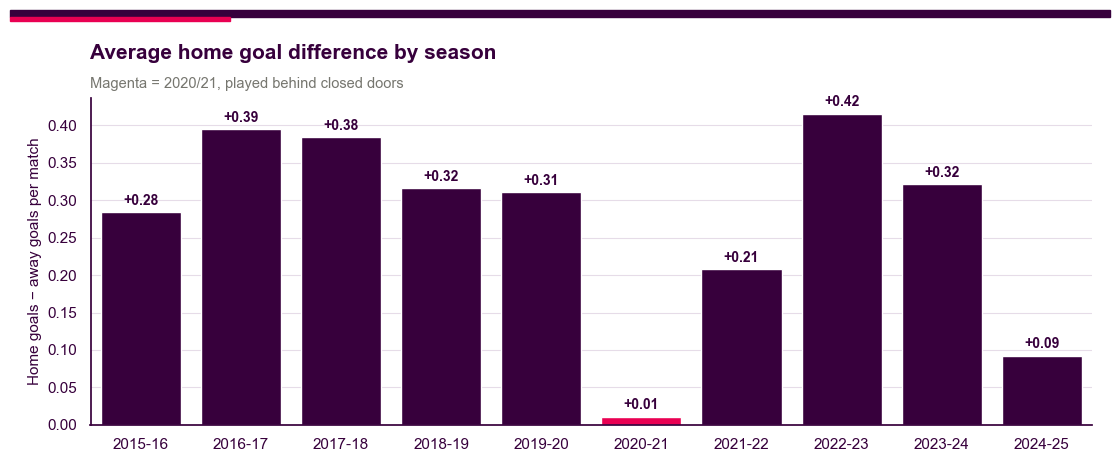

In [39]:
home_summary = (
    matches.assign(home_win=matches["FTR"].eq("H"), draw=matches["FTR"].eq("D"), away_win=matches["FTR"].eq("A"),
                   home_gd=matches["FTHG"] - matches["FTAG"])
    .groupby("season", as_index=False)
    .agg(Matches=("match_id", "count"), Home_win=("home_win", "mean"), Draw=("draw", "mean"),
         Away_win=("away_win", "mean"), Home_GD=("home_gd", "mean"))
)
display(pl_table(home_summary.rename(columns={"Home_win": "Home win %", "Away_win": "Away win %", "Home_GD": "Avg home GD"}),
                 precision=3, highlight_first=False))

# 100%-stacked bars of match outcomes per season, with the behind-closed-doors season flagged
fig_home = go.Figure()
for col, label, color in [("Home_win", "Home win", PL["purple"]), ("Draw", "Draw", "#BDB3C0"), ("Away_win", "Away win", PL["pink"])]:
    fig_home.add_trace(go.Bar(x=home_summary["season"], y=home_summary[col], name=label, marker_color=color,
                              text=[f"{v:.0%}" for v in home_summary[col]], textposition="inside",
                              textfont=dict(color="white" if color != "#BDB3C0" else PL["purple"]),
                              hovertemplate=f"<b>{label}</b> · %{{x}}: %{{y:.1%}}<extra></extra>"))
fig_home.add_annotation(x="2020-21", y=1.04, text="<b>No fans (COVID-19)</b>", showarrow=False,
                        font=dict(color=PL["pink"], size=12))
fig_home.update_layout(barmode="stack", title=pl_title("Match outcomes by season", "Share of all 380 matches · click legend to isolate an outcome"),
                       yaxis=dict(tickformat=".0%", range=[0, 1.08], title="Share of matches"),
                       xaxis=dict(title="Season", rangeslider=dict(visible=True, bgcolor=PL["light"], thickness=0.06)),
                       height=560, legend=dict(traceorder="normal"))
fig_home.show()

# Average home goal difference per match, with 2020-21 highlighted
fig, ax = plt.subplots(figsize=(11, 4.6))
colors = [PL["pink"] if s == "2020-21" else PL["purple"] for s in home_summary["season"]]
sns.barplot(data=home_summary, x="season", y="Home_GD", hue="season", palette=colors, legend=False, saturation=1, ax=ax)
for i, v in enumerate(home_summary["Home_GD"]):
    ax.text(i, v + 0.01, f"{v:+.2f}", ha="center", fontweight="bold", fontsize=10)
ax.set(xlabel="", ylabel="Home goals − away goals per match")
pl_mpl_title(ax, "Average home goal difference by season", "Magenta = 2020/21, played behind closed doors")
show_mpl(fig)

### 6.2 · Feature engineering: pre-match information

Every feature is known **before kick-off**, so no match ever sees its own result.

| Group | Features | How it is built |
|---|---|---|
| **Form** | Points, goals for/against, win rate and goal difference over each club's last 5 matches; matches played | Rolling means of *past* matches (`.shift(1)` excludes the current one) |
| **Elo rating** | Home Elo, away Elo, Elo difference | A rating that rises after wins and falls after losses, weighted by how surprising the result was and the winning margin. It captures long-run strength that a 5-match window misses. Promoted clubs start at the lowest rating from the season before. |
| **Market odds** | Implied probability of a home win, draw and away win, and of over 2.5 goals | `1 / decimal odds` from the pre-match odds in the football-data files, rescaled to sum to 1 (this removes the bookmaker's margin) |

In [40]:
ELO_START, ELO_K, ELO_HOME_ADV = 1500, 20, 60       # start rating, update speed, home-advantage bonus (rating points)
ROLLING_SOURCES = {"points": "points", "gf": "goals_for", "ga": "goals_against", "win_flag": "win_rate", "gd": "goal_difference"}
FORM_COLS = [f"form_{label}_5" for label in ROLLING_SOURCES.values()] + ["matches_played_before"]
FORM_FEATURES = [f"{side}_{c}" for side in ("home", "away") for c in FORM_COLS]
ELO_FEATURES = ["home_elo", "away_elo", "elo_diff"]
ODDS_FEATURES = ["p_home", "p_draw", "p_away", "p_over25"]
match_feature_cols = FORM_FEATURES + ELO_FEATURES + ODDS_FEATURES


def build_match_features(match_df):
    """Add form, Elo and odds features to every match. Every feature uses only information from before kick-off.

    Returns (match data with features, final Elo ratings). Written as a function so §8 can rebuild the
    features for the 2025/26 season with exactly the same logic.
    """
    match_df = match_df.sort_values("match_id").reset_index(drop=True)

    # ── Form: one row per club per match (home and away perspectives), in date order ──
    rows = []
    for side, team_col, gf, ga, win_code in [("home", "HomeTeam", "FTHG", "FTAG", "H"), ("away", "AwayTeam", "FTAG", "FTHG", "A")]:
        r = match_df[["match_id", "match_date", team_col, gf, ga, "FTR"]].rename(columns={team_col: "team", gf: "gf", ga: "ga"})
        r["points"] = np.select([r["FTR"] == win_code, r["FTR"] == "D"], [3, 1], default=0)
        r["win_flag"] = (r["FTR"] == win_code).astype(int)
        r["side"] = side
        rows.append(r)
    history = pd.concat(rows, ignore_index=True)
    history["gd"] = history["gf"] - history["ga"]
    history = history.sort_values(["team", "match_date", "match_id"]).reset_index(drop=True)
    # Rolling 5-match means of PAST matches only (shift(1) excludes the current match)
    for raw_col, label in ROLLING_SOURCES.items():
        history[f"form_{label}_5"] = history.groupby("team")[raw_col].transform(
            lambda s: s.shift(1).rolling(window=5, min_periods=1).mean())
    history["matches_played_before"] = history.groupby("team").cumcount()
    # Pivot back to one row per match with home_* and away_* feature columns
    home_form = history[history["side"] == "home"].set_index("match_id")[FORM_COLS].add_prefix("home_")
    away_form = history[history["side"] == "away"].set_index("match_id")[FORM_COLS].add_prefix("away_")
    data = match_df.join(home_form, on="match_id").join(away_form, on="match_id")

    # ── Elo ratings, updated match by match in date order ──
    ratings, home_elo, away_elo, current_season, season_clubs = {}, [], [], None, set()
    for row in data.itertuples():
        if row.season != current_season:
            # Each summer: keep only last season's clubs, pull their ratings 25% back towards average, and give every
            # promoted club (even one returning after years away) the lowest of those ratings, usually a relegated side's.
            ratings = {team: 0.75 * rating + 0.25 * ELO_START for team, rating in ratings.items() if team in season_clubs}
            promoted_rating = min(ratings.values()) if ratings else ELO_START
            current_season, season_clubs = row.season, set()
        season_clubs.update([row.HomeTeam, row.AwayTeam])
        h = ratings.setdefault(row.HomeTeam, promoted_rating)
        a = ratings.setdefault(row.AwayTeam, promoted_rating)
        home_elo.append(h)                                # record the PRE-match ratings as features
        away_elo.append(a)
        expected_home = 1 / (1 + 10 ** ((a - h - ELO_HOME_ADV) / 400))
        actual_home = {"H": 1.0, "D": 0.5, "A": 0.0}[row.FTR]
        margin = np.log(abs(row.FTHG - row.FTAG) + 1) + 1 if row.FTHG != row.FTAG else 1.0   # bigger wins move ratings more
        change = ELO_K * margin * (actual_home - expected_home)
        ratings[row.HomeTeam], ratings[row.AwayTeam] = h + change, a - change
    data["home_elo"], data["away_elo"] = home_elo, away_elo
    data["elo_diff"] = data["home_elo"] - data["away_elo"]

    # ── Market-implied probabilities from pre-match odds ──
    implied = 1 / data[["B365H", "B365D", "B365A"]]
    implied = implied.div(implied.sum(axis=1), axis=0)                # remove the bookmaker margin
    data["p_home"], data["p_draw"], data["p_away"] = implied.to_numpy().T
    # Over/under 2.5 goals odds: column names changed over time, so take whichever exists for each season
    def first_available(*cols):
        out = pd.Series(np.nan, index=data.index)
        for col in cols:
            if col in data:
                out = out.combine_first(data[col])
        return out
    over, under = first_available("Avg>2.5", "BbAv>2.5", "B365>2.5"), first_available("Avg<2.5", "BbAv<2.5", "B365<2.5")
    data["p_over25"] = (1 / over) / (1 / over + 1 / under)
    return data, ratings


match_model_data, elo = build_match_features(matches)

# Chronological split: train → validation (model choice) → test (final score)
test_year = matches["season_start_year"].max()
val_year = test_year - 1
match_train = match_model_data[match_model_data["season_start_year"] < val_year]
match_val = match_model_data[match_model_data["season_start_year"] == val_year]
match_train_full = match_model_data[match_model_data["season_start_year"] < test_year]     # train + validation
match_test = match_model_data[match_model_data["season_start_year"] == test_year]
print(f"{len(match_feature_cols)} features ({len(FORM_FEATURES)} form · {len(ELO_FEATURES)} Elo · {len(ODDS_FEATURES)} odds) · "
      f"train {len(match_train):,} · validation {len(match_val):,} · test {len(match_test):,} matches")

# Final Elo table: a quick sanity check that the ratings make sense
display(pl_table(pd.DataFrame(sorted(elo.items(), key=lambda kv: -kv[1])[:8], columns=["Club", "Elo after 2024/25"]),
                 precision=0))

19 features (12 form · 3 Elo · 4 odds) · train 3,040 · validation 380 · test 380 matches


Club,Elo after 2024/25
Liverpool,"1,694"
Arsenal,"1,679"
Man City,"1,676"
Chelsea,"1,599"
Aston Villa,"1,580"
Newcastle,"1,561"
Brighton,"1,551"
Crystal Palace,"1,542"


### 6.3 · Experiment 3: predict the result (home win / draw / away win)

**Step 1, choose the model.** Three candidates are fitted on 2015/16–2022/23 and compared on the 2023/24 validation season. They are compared by **log loss**, which measures how good the predicted *probabilities* are (lower is better), not just the top pick.

**Step 2, test it.** The winner is refitted on 2015/16–2023/24 and scored on 2024/25.

**Baselines:** "always predict a home win", plus a tougher benchmark, *"pick the bookmakers' favourite"*. **Metrics:** accuracy, and macro-F1, which weights home wins, draws and away wins equally.

In [41]:
OUTCOMES = ["H", "D", "A"]
OUTCOME_NAMES = ["Home win", "Draw", "Away win"]

# Candidate models (pl_analytics/models.py)
outcome_candidates = candidate_outcome_models()

# Step 1: model selection on the validation season
selection = []
for name, make in outcome_candidates.items():
    candidate = make().fit(match_train[match_feature_cols], match_train["FTR"])
    selection.append({"Model": name,
                      "Validation accuracy": accuracy_score(match_val["FTR"], candidate.predict(match_val[match_feature_cols])),
                      "Validation log loss": log_loss(match_val["FTR"], candidate.predict_proba(match_val[match_feature_cols]),
                                                      labels=candidate.classes_)})
selection = pd.DataFrame(selection).sort_values("Validation log loss").reset_index(drop=True)
best_outcome_name = selection.loc[0, "Model"]
print(f"Model selection on {season_label(val_year)} → chosen: {best_outcome_name}")
display(pl_table(selection, precision=3))

Model selection on 2023-24 → chosen: Logistic regression


Model,Validation accuracy,Validation log loss
Logistic regression,0.579,0.915
Random forest,0.584,0.918
Gradient boosting,0.532,0.996


In [42]:
# Step 2: refit the chosen model on train + validation, then score the untouched test season
X_fit, y_fit = match_train_full[match_feature_cols], match_train_full["FTR"]
X_test_match, y_test_match = match_test[match_feature_cols], match_test["FTR"]
outcome_model = outcome_candidates[best_outcome_name]().fit(X_fit, y_fit)
pred_outcome = outcome_model.predict(X_test_match)
baseline_outcome = DummyClassifier(strategy="most_frequent").fit(X_fit, y_fit).predict(X_test_match)
bookmaker_pick = np.array(OUTCOMES)[match_test[["p_home", "p_draw", "p_away"]].to_numpy().argmax(axis=1)]

match_result_metrics = pd.DataFrame([
    {"Model": f"{best_outcome_name} (form + Elo + odds)", "Accuracy": accuracy_score(y_test_match, pred_outcome),
     "Macro F1": f1_score(y_test_match, pred_outcome, average="macro")},
    {"Model": "Baseline: always home win", "Accuracy": accuracy_score(y_test_match, baseline_outcome),
     "Macro F1": f1_score(y_test_match, baseline_outcome, average="macro", zero_division=0)},
    {"Model": "Benchmark: bookmakers' favourite", "Accuracy": accuracy_score(y_test_match, bookmaker_pick),
     "Macro F1": f1_score(y_test_match, bookmaker_pick, average="macro", zero_division=0)},
])
display(pl_table(match_result_metrics, precision=3))
add_experiment_result("3", "Q5 Match prediction", "Result: H / D / A", best_outcome_name, "Accuracy",
                      match_result_metrics.loc[0, "Accuracy"], "Always home win", match_result_metrics.loc[1, "Accuracy"], True)
print(classification_report(y_test_match, pred_outcome, labels=OUTCOMES, target_names=OUTCOME_NAMES, zero_division=0))

# Ablation: how much does each feature group add? (same model type, same split)
ablation = []
for label, cols in [("Form only", FORM_FEATURES), ("Form + Elo", FORM_FEATURES + ELO_FEATURES),
                    ("Form + Elo + odds", match_feature_cols)]:
    m = outcome_candidates[best_outcome_name]().fit(match_train_full[cols], y_fit)
    ablation.append({"Features": label, "Test accuracy": accuracy_score(y_test_match, m.predict(match_test[cols])),
                     "Test log loss": log_loss(y_test_match, m.predict_proba(match_test[cols]), labels=m.classes_)})
ablation = pd.DataFrame(ablation)
display(pl_table(ablation, precision=3, highlight_first=False))

Model,Accuracy,Macro F1
Logistic regression (form + Elo + odds),0.545,0.406
Baseline: always home win,0.408,0.193
Benchmark: bookmakers' favourite,0.539,0.404


              precision    recall  f1-score   support

    Home win       0.53      0.87      0.66       155
        Draw       0.00      0.00      0.00        93
    Away win       0.58      0.55      0.56       132

    accuracy                           0.54       380
   macro avg       0.37      0.47      0.41       380
weighted avg       0.42      0.54      0.46       380



Features,Test accuracy,Test log loss
Form only,0.466,1.061
Form + Elo,0.524,0.980
Form + Elo + odds,0.545,0.977


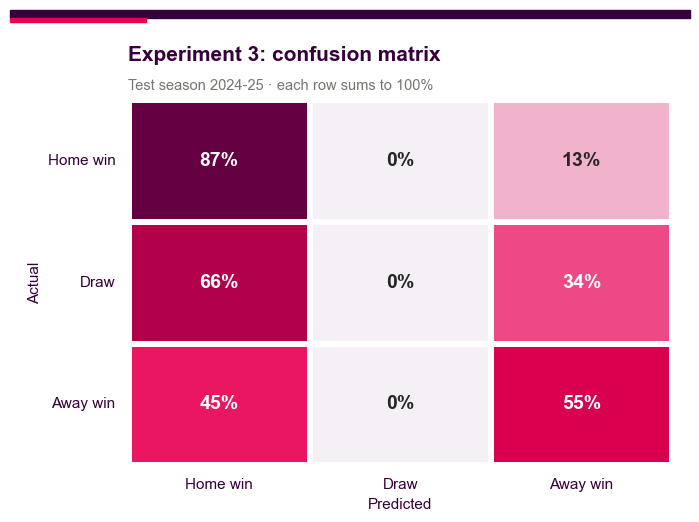

In [43]:
# Confusion matrix as row percentages: each row shows how that actual outcome was predicted
cm = confusion_matrix(y_test_match, pred_outcome, labels=OUTCOMES)
cm_share = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(6.8, 5.2))
sns.heatmap(cm_share, annot=True, fmt=".0%", cmap=PL_CMAP, vmin=0, vmax=1, cbar=False, linewidths=3, linecolor="white",
            xticklabels=OUTCOME_NAMES, yticklabels=OUTCOME_NAMES, annot_kws={"fontsize": 14, "fontweight": "bold"}, ax=ax)
ax.set(xlabel="Predicted", ylabel="Actual")
ax.tick_params(axis="y", rotation=0)
pl_mpl_title(ax, "Experiment 3: confusion matrix", f"Test season {season_label(test_year)} · each row sums to 100%")
show_mpl(fig)

**Can the probabilities be trusted? Calibration.** A useful model is not just right often: when it says "60% home win", home teams should win about 60% of those matches. The chart pools every predicted probability (home, draw and away) on the 2024/25 test season, groups them into bins, and compares the average predicted chance with how often that outcome actually happened. Points on the diagonal are perfectly calibrated. The **Brier score** summarises the same idea in one number (lower is better).

In [44]:
classes = list(outcome_model.classes_)                        # e.g. ['A', 'D', 'H']
odds_cols = {"H": "p_home", "D": "p_draw", "A": "p_away"}
test_proba = outcome_model.predict_proba(X_test_match)
book_proba = match_test[[odds_cols[c] for c in classes]].to_numpy()
base_rates = y_fit.value_counts(normalize=True).reindex(classes).to_numpy()
model_label = f"{best_outcome_name} (form + Elo + odds)"

brier_table = pd.DataFrame([
    {"Predictor": model_label, "Brier score": brier_score(y_test_match, test_proba, classes)},
    {"Predictor": "Bookmakers' odds", "Brier score": brier_score(y_test_match, book_proba, classes)},
    {"Predictor": "Base rates", "Brier score": brier_score(y_test_match, np.tile(base_rates, (len(y_test_match), 1)), classes)},
])
display(pl_table(brier_table, precision=4))

# Average predicted chance vs actual frequency per outcome: shows the model does price in draws
outcome_check = pd.DataFrame([
    {"Outcome": name, "Average predicted chance": test_proba[:, classes.index(code)].mean(),
     "Actual frequency": (y_test_match == code).mean()}
    for code, name in zip(OUTCOMES, OUTCOME_NAMES)])
display(pl_table(outcome_check, precision=3, highlight_first=False))

fig_calib = go.Figure()
fig_calib.add_shape(type="line", x0=0, y0=0, x1=1, y1=1, line=dict(dash="dash", color=PL["grey"]))
for label, proba, color in [(model_label, test_proba, PL["pink"]), ("Bookmakers' odds", book_proba, PL["purple"])]:
    rel = reliability_table(y_test_match, proba, classes)
    fig_calib.add_trace(go.Scatter(x=rel["Predicted chance"], y=rel["Observed frequency"], mode="lines+markers", name=label,
                                   line=dict(color=color, width=3), marker=dict(size=10),
                                   hovertemplate="Predicted %{x:.0%} → happened %{y:.0%}<extra>" + label + "</extra>"))
fig_calib.update_layout(title=pl_title(f"Calibration: predicted chance vs actual frequency · {season_label(test_year)}",
                                       "Each point = one bin of probabilities · dashed line = perfectly calibrated"),
                        xaxis=dict(title="Predicted chance", tickformat=".0%", range=[0, 1]),
                        yaxis=dict(title="How often it happened", tickformat=".0%", range=[0, 1]), height=560)
fig_calib.show()

Predictor,Brier score
Logistic regression (form + Elo + odds),0.5826
Bookmakers' odds,0.5787
Base rates,0.6557


Outcome,Average predicted chance,Actual frequency
Home win,0.476,0.408
Draw,0.209,0.245
Away win,0.315,0.347


### 6.4 · Experiment 4: predict the score (home and away goals)

**Model:** Poisson regression, one model each for home and away goals. Goals are rare, whole-number events, which is exactly what a Poisson model is built for: it predicts an *expected* number of goals, always ≥ 0. It uses the same pre-match features as Experiment 3 (the over/under 2.5 odds carry most of the "how many goals" signal) and is trained on 2015/16–2023/24.

**Baseline:** predict the training-set average for every match. **Metrics:** MAE and RMSE in goals, and Poisson deviance (the natural error measure for count predictions; lower is better).

In [45]:
goal_targets = ["FTHG", "FTAG"]
goal_model = make_goal_model()                          # Poisson regression per target (pl_analytics/models.py)
goal_model.fit(match_train_full[match_feature_cols], match_train_full[goal_targets])
pred_goals = goal_model.predict(match_test[match_feature_cols])
baseline_goals = (DummyRegressor(strategy="mean").fit(match_train_full[match_feature_cols], match_train_full[goal_targets])
                  .predict(match_test[match_feature_cols]))

goal_metrics = pd.DataFrame([
    {"Target": label, "Model MAE": mean_absolute_error(match_test[t], pred_goals[:, i]),
     "Baseline MAE": mean_absolute_error(match_test[t], baseline_goals[:, i]),
     "Model RMSE": mean_squared_error(match_test[t], pred_goals[:, i]) ** 0.5,
     "Baseline RMSE": mean_squared_error(match_test[t], baseline_goals[:, i]) ** 0.5,
     "Model deviance": mean_poisson_deviance(match_test[t], pred_goals[:, i]),
     "Baseline deviance": mean_poisson_deviance(match_test[t], baseline_goals[:, i])}
    for i, (t, label) in enumerate(zip(goal_targets, ["Home goals", "Away goals"]))
])
display(pl_table(goal_metrics, precision=3, highlight_first=False))
add_experiment_result("4", "Q5 Match prediction", "Home & away goals", "Poisson regression", "MAE (goals, avg of home/away)",
                      goal_metrics["Model MAE"].mean(), "Training average", goal_metrics["Baseline MAE"].mean(), False)

# Distribution of predicted goals for each actual goal count: a good model's boxes climb from left to right
long = pd.concat([
    pd.DataFrame({"Actual goals": match_test["FTHG"].clip(upper=5).values, "Predicted goals": pred_goals[:, 0], "Side": "Home"}),
    pd.DataFrame({"Actual goals": match_test["FTAG"].clip(upper=5).values, "Predicted goals": pred_goals[:, 1], "Side": "Away"}),
])
long["Actual goals"] = long["Actual goals"].astype(int).astype(str).replace({"5": "5+"})
fig_goals = px.box(long, x="Actual goals", y="Predicted goals", color="Side", points=False,
                   color_discrete_map={"Home": PL["purple"], "Away": PL["pink"]},
                   category_orders={"Actual goals": ["0", "1", "2", "3", "4", "5+"]})
fig_goals.update_layout(title=pl_title("Experiment 4: predicted goals by actual goals scored",
                                       f"Test season {season_label(test_year)} · boxes rising left → right = the model separates low- and high-scoring sides"),
                        height=520)
fig_goals.show()

Target,Model MAE,Baseline MAE,Model RMSE,Baseline RMSE,Model deviance,Baseline deviance
Home goals,0.978,1.054,1.216,1.277,1.129,1.247
Away goals,0.856,0.920,1.096,1.199,0.985,1.140


### 6.5 · Result

In [46]:
covid = home_summary.set_index("season").loc["2020-21"]
normal = home_summary[home_summary["season"] != "2020-21"]
acc_model, acc_base, acc_book = match_result_metrics["Accuracy"].tolist()
FINAL_ANSWERS["Q5"] = (
    "Q5 · Home advantage and match predictability",
    f"🏟️ Home win rate {normal['Home_win'].mean():.0%} with fans vs {covid['Home_win']:.0%} without",
    f"With crowds, home teams won {normal['Home_win'].mean():.1%} of matches (average home GD {normal['Home_GD'].mean():+.2f}). "
    f"In the behind-closed-doors 2020/21 season, that fell to {covid['Home_win']:.1%} (GD {covid['Home_GD']:+.2f}) and away wins "
    f"({covid['Away_win']:.1%}) out-numbered home wins. Using form, Elo and odds, the result model is right "
    f"<b>{acc_model:.1%}</b> of the time (vs {acc_base:.1%} for 'always home win' and {acc_book:.1%} for the bookmakers' favourite), "
    f"and the goals model's MAE is {goal_metrics['Model MAE'].mean():.2f} vs {goal_metrics['Baseline MAE'].mean():.2f} for the average.",
)
result_card(*FINAL_ANSWERS["Q5"])

In [47]:
# Key takeaways, written from the results above
away_beat_home = home_summary.loc[home_summary["Away_win"] > home_summary["Home_win"], "season"].tolist()
latest_home = home_summary.iloc[-1]
ablation_acc = ablation.set_index("Features")["Test accuracy"]
n_draw_picks = int((pred_outcome == "D").sum())
n_draws = int((y_test_match == "D").sum())
versus_book = "beats" if acc_model > acc_book + 0.01 else ("matches" if acc_model >= acc_book - 0.01 else "falls short of")   # ±1 point = a tie
brier = brier_table.set_index("Predictor")["Brier score"]
model_brier, book_brier = brier[model_label], brier["Bookmakers' odds"]
draw_check = outcome_check.set_index("Outcome").loc["Draw"]
goal_mae, goal_base = goal_metrics["Model MAE"].mean(), goal_metrics["Baseline MAE"].mean()

takeaways(
    f"**Home advantage is real, and crowds drive it.** With fans, home teams won {normal['Home_win'].mean():.1%} of matches. "
    f"In behind-closed-doors 2020/21 they won only {covid['Home_win']:.1%}, and away wins ({covid['Away_win']:.1%}) out-numbered home wins"
    + (" for the only time in the decade" if away_beat_home == ["2020-21"] else f" (as also in {', '.join(s for s in away_beat_home if s != '2020-21')})")
    + f". The average home goal difference fell from {normal['Home_GD'].mean():+.2f} to {covid['Home_GD']:+.2f}.",
    f"**{latest_home['season']}:** {latest_home['Home_win']:.1%} home wins and an average home goal difference of {latest_home['Home_GD']:+.2f}"
    + (", one of the weakest home records outside 2020/21." if latest_home["Home_win"] < normal["Home_win"].mean() - 0.03 else "."),
    f"**Pre-match information makes results fairly predictable.** The result model is right {acc_model:.1%} of the time, "
    f"against {acc_base:.1%} for always picking a home win, and {versus_book} the bookmakers' favourite ({acc_book:.1%}). "
    f"Where the gain comes from: form alone {ablation_acc['Form only']:.1%} → adding Elo {ablation_acc['Form + Elo']:.1%} → "
    f"adding odds {ablation_acc['Form + Elo + odds']:.1%}.",
    f"**Draws are almost never the single most likely outcome.** The model picked a draw {n_draw_picks} time"
    f"{'s' if n_draw_picks != 1 else ''}, against {n_draws} actual draws ({n_draws / len(y_test_match):.0%} of matches). "
    f"Its probabilities still allow for them: an average draw chance of {draw_check['Average predicted chance']:.0%} "
    f"vs an actual rate of {draw_check['Actual frequency']:.0%}.",
    f"**The probabilities are {'about as trustworthy as' if model_brier <= book_brier + 0.005 else 'less trustworthy than'} "
    f"the bookmakers'**: Brier score {model_brier:.3f} vs {book_brier:.3f} (base rates {brier['Base rates']:.3f}; lower is better).",
    f"**The goals model {'beats' if goal_mae < goal_base else 'does not beat'} the average** (MAE {goal_mae:.2f} vs {goal_base:.2f}; "
    f"Poisson deviance {goal_metrics['Model deviance'].mean():.2f} vs {goal_metrics['Baseline deviance'].mean():.2f}).",
)

**Key takeaways**

* **Home advantage is real, and crowds drive it.** With fans, home teams won 45.2% of matches. In behind-closed-doors 2020/21 they won only 37.9%, and away wins (40.3%) out-numbered home wins for the only time in the decade. The average home goal difference fell from +0.30 to +0.01.
* **2024-25:** 40.8% home wins and an average home goal difference of +0.09, one of the weakest home records outside 2020/21.
* **Pre-match information makes results fairly predictable.** The result model is right 54.5% of the time, against 40.8% for always picking a home win, and matches the bookmakers' favourite (53.9%). Where the gain comes from: form alone 46.6% → adding Elo 52.4% → adding odds 54.5%.
* **Draws are almost never the single most likely outcome.** The model picked a draw 0 times, against 93 actual draws (24% of matches). Its probabilities still allow for them: an average draw chance of 21% vs an actual rate of 24%.
* **The probabilities are about as trustworthy as the bookmakers'**: Brier score 0.583 vs 0.579 (base rates 0.656; lower is better).
* **The goals model beats the average** (MAE 0.92 vs 0.99; Poisson deviance 1.06 vs 1.19).

---
# 7 · Reality check: predictions vs the actual 2025/26 season

Everything above uses data up to the end of 2024/25, plus two things published before 2025/26 kicked off: the Gameweek 1 squad list and the fixture list. The 2025/26 season has now finished, so every forecast can be checked against what actually happened. This is the purest test in the notebook: **none of the 2025/26 data below was used to train, tune or choose any model.**

| What was predicted | Checked against | Section |
|---|---|:-:|
| Q1 club strength (Club Score and pre-season Elo ranking) | The actual 2025/26 league table | §7.2 |
| Q2 best players | Actual 2025/26 FPL points | §7.3 |
| Q3 player points and the best XI (Experiment 1) | Each player's actual 2025/26 FPL points | §7.4 |
| Q4 FPL prices (Experiment 2) | Actual end-of-season 2025/26 prices | §7.5 |
| Q5 match results and goals (Experiments 3 & 4) | All 380 matches of 2025/26 | §7.6 |

> **Two things changed in 2025/26 that no model trained on earlier seasons could know:**
> 1. **FPL scoring rules.** FPL added *defensive contribution* points, awarded for clearances, blocks, interceptions, tackles and recoveries. These reward defenders and defensive midfielders, a scoring source that did not exist in the training data.
> 2. **Late transfers and injuries.** The forecasts are transfer-aware up to Gameweek 1 (§1.2b), but moves after GW1 (e.g. Isak to Liverpool on deadline day), loans abroad and long injuries were still invisible.

All matching between seasons uses FPL's stable player ID, so name changes (e.g. "Muñoz" → "Muñoz Mejía") cannot cause false misses.

### 7.1 · Load the actual 2025/26 data

In [48]:
ACTUAL_SEASON = season_label(latest_year + 1)                       # "2025-26"
matches_actual = load_match_season(ACTUAL_SEASON)                    # same loader and cleaning as §1.1
fpl_actual = load_fpl_actual(ACTUAL_SEASON, matches)                 # final 2025/26 FPL points and prices, by stable ID
actual_by_id = fpl_actual.set_index("player_id")


def attach_actual(df, cols):
    """Add 2025/26 actual columns by stable player ID (immune to name and position changes)."""
    return df.drop(columns=[c for c in cols if c in df]).join(actual_by_id[cols], on="player_id")


table_actual = league_table(matches_actual)
stat_tiles([
    ("Season", ACTUAL_SEASON.replace("-", "/")),
    ("Matches", len(matches_actual)),
    ("Champions", table_actual.loc[0, "team"]),
    ("Top FPL scorer", f"{fpl_actual.loc[fpl_actual['actual_points'].idxmax(), 'web_name']} "
                       f"({fpl_actual['actual_points'].max()} pts)"),
    ("FPL players", f"{len(fpl_actual):,}"),
])

### 7.2 · Q1 check: club strength vs the 2025/26 table

The notebook's closest thing to a club forecast is the **Elo rating at the end of 2024/25**: it is the model's view of each club's strength going into 2025/26. As in §6.2, promoted clubs enter with the lowest rating from 2024/25 (a relegated side's), so the three of them share 18th. How well does that ranking match the final table?

In [49]:
# Pre-season ranking = Elo after 2024/25 with the same summer adjustment as §6.2 (promoted clubs share the lowest rating)
clubs_2425 = set(matches.loc[matches["season"] == SEASON_LABELS[-1], "HomeTeam"])
pre_season_elo = {team: 0.75 * rating + 0.25 * ELO_START for team, rating in elo.items() if team in clubs_2425}
promoted_rating = min(pre_season_elo.values())
club_check = table_actual[["Position", "team", "Points", "GD"]].copy()
club_check["Pre-season Elo"] = club_check["team"].map(pre_season_elo).fillna(promoted_rating)
club_check["Predicted rank"] = club_check["Pre-season Elo"].rank(ascending=False, method="min").astype(int)
club_check["Rank error"] = club_check["Position"] - club_check["Predicted rank"]      # + = finished lower than predicted
club_check["Promoted"] = ~club_check["team"].isin(clubs_2425)

rank_corr = club_check["Predicted rank"].corr(club_check["Position"], method="spearman")
top4_hits = len(set(club_check.nsmallest(4, "Predicted rank")["team"]) & set(club_check.nsmallest(4, "Position")["team"]))
releg_hits = len(set(club_check.nlargest(3, "Predicted rank")["team"]) & set(club_check.nlargest(3, "Position")["team"]))
best_club_pos = int(club_check.loc[club_check["team"] == best["team"], "Position"].iloc[0])
print(f"Rank correlation (Spearman) between pre-season Elo and the final table: {rank_corr:.2f}  (1 = perfect order)")
print(f"Top four correctly identified: {top4_hits}/4 · bottom three: {releg_hits}/3 · "
      f"Q1's best club ({best['team']}) finished {best_club_pos}")

display(pl_table(club_check.rename(columns={"team": "Club"}).drop(columns="Promoted"), precision=0, highlight_first=False))

# Predicted rank vs actual position: points on the dashed line were ranked exactly right
fig_clubcheck = go.Figure()
fig_clubcheck.add_shape(type="line", x0=0.5, y0=0.5, x1=20.5, y1=20.5, line=dict(dash="dash", color=PL["grey"]))
fig_clubcheck.add_trace(go.Scatter(
    x=club_check["Predicted rank"], y=club_check["Position"], mode="markers+text", text=club_check["team"],
    textposition="middle right", textfont=dict(size=11, color=PL["purple"]),
    marker=dict(size=16, color=[club_color(t) for t in club_check["team"]], line=dict(color="white", width=2),
                symbol=["diamond" if p else "circle" for p in club_check["Promoted"]]),
    customdata=club_check[["Points", "Rank error"]].to_numpy(),
    hovertemplate="<b>%{text}</b><br>Predicted rank %{x} · finished %{y}<br>%{customdata[0]} pts · "
                  "rank error %{customdata[1]:+d}<extra></extra>"))
fig_clubcheck.update_layout(
    title=pl_title(f"Pre-season Elo ranking vs final {ACTUAL_SEASON} position",
                   f"Spearman ρ = {rank_corr:.2f} · dashed line = perfect forecast · ◆ = promoted club"),
    xaxis=dict(title="Predicted rank (pre-season Elo)", range=[0.2, 22.5], dtick=1),
    yaxis=dict(title="Actual finishing position", range=[20.8, 0.2], dtick=1), height=640, showlegend=False)
fig_clubcheck.show()

Rank correlation (Spearman) between pre-season Elo and the final table: 0.53  (1 = perfect order)
Top four correctly identified: 2/4 · bottom three: 1/3 · Q1's best club (Man City) finished 2


Position,Club,Points,GD,Pre-season Elo,Predicted rank,Rank error
1,Arsenal,85,44,"1,635",2,-1
2,Man City,78,42,"1,632",3,-1
3,Man United,71,19,"1,423",16,-13
4,Aston Villa,65,7,"1,560",5,-1
5,Liverpool,60,10,"1,645",1,4
6,Bournemouth,57,4,"1,503",12,-6
7,Sunderland,54,-6,"1,230",18,-11
8,Brighton,53,6,"1,538",7,1
9,Brentford,53,3,"1,506",11,-2
10,Chelsea,52,6,"1,574",4,6


### 7.3 · Q2 check: did the best players stay the best?

In [50]:
# Where did the Q2 leaders land in the 2025/26 FPL points ranking?
latest_id = fpl_players.sort_values("season_start_year").drop_duplicates("player", keep="last").set_index("player")["player_id"]
q2_leaders = fpl_top_players.head(10)[["player", "Position", "FPL_points"]].assign(player_id=lambda d: d["player"].map(latest_id))
q2_check = attach_actual(q2_leaders, ["team_2526", "actual_points", "actual_rank"])
q2_check["2025/26 status"] = np.select(
    [q2_check["actual_points"].isna(), q2_check["actual_points"] == 0],
    ["Not in the 2025/26 PL", "Did not play (loaned out / left)"],
    default="Rank " + q2_check["actual_rank"].astype("Int64").astype(str))
display(pl_table(q2_check[["player", "Position", "FPL_points", "team_2526", "actual_points", "2025/26 status"]]
                 .rename(columns={"FPL_points": "Career pts 2016–25", "team_2526": "2025/26 club",
                                  "actual_points": "2025/26 pts"}), precision=0))

print(f"Top 10 FPL scorers of {ACTUAL_SEASON}:")
display(pl_table(fpl_actual.nlargest(10, "actual_points")[["web_name", "position", "team", "actual_points",
                                                           "actual_minutes", "defensive_contribution"]]
                 .rename(columns={"web_name": "Player", "actual_points": "Points", "actual_minutes": "Minutes",
                                  "defensive_contribution": "Defensive contributions"}), precision=0))

player,Position,Career pts 2016–25,2025/26 club,2025/26 pts,2025/26 status
Mohamed Salah,MID,"2,085",Liverpool,123,Rank 77
Harry Kane,FWD,"1,456",nan,nan,Not in the 2025/26 PL
Kevin De Bruyne,MID,"1,450",nan,nan,Not in the 2025/26 PL
Raheem Sterling,MID,"1,383",nan,nan,Not in the 2025/26 PL
Trent Alexander-Arnold,DEF,"1,280",nan,nan,Not in the 2025/26 PL
Jamie Vardy,FWD,"1,258",nan,nan,Not in the 2025/26 PL
Andrew Robertson,DEF,"1,213",Liverpool,55,Rank 276
Jordan Pickford,GK,"1,190",Everton,135,Rank 47
Heung-Min Son,MID,"1,166",Tottenham,0,Did not play (loaned out / left)
Marcus Rashford,MID,"1,130",Man United,0,Did not play (loaned out / left)


Top 10 FPL scorers of 2025-26:


Player,position,team,Points,Minutes,Defensive contributions
Haaland,FWD,Man City,239,"2,953",104
B.Fernandes,MID,Man United,235,"3,065",287
Gabriel,DEF,Arsenal,209,"2,750",277
Semenyo,MID,Man City,202,"3,200",236
Gibbs-White,MID,Nott'm Forest,188,"3,101",178
Bowen,FWD,West Ham,187,"3,406",281
Rice,MID,Arsenal,184,"3,093",376
Thiago,FWD,Brentford,181,"3,282",214
Anderson,MID,Nott'm Forest,180,"3,332",515
Guéhi,DEF,Man City,179,"3,150",278


### 7.4 · Q3 / Experiment 1 check: predicted vs actual 2025/26 points

Each 2025/26 projection from §4.4 (players in the GW1 squad list) is matched to the player's actual season by stable ID. The baseline is the same as before: *"the same points as 2024/25"*.

In [51]:
proj = predicted_points_next[["player", "web_name", "player_id", "position", "team", "total_points",
                              "now_cost", "predicted_next_points", "points_low", "points_high"]]
points_check = attach_actual(proj, ["team_2526", "actual_points", "actual_minutes"])
points_check["left_pl"] = points_check["actual_points"].isna()
matched = points_check[~points_check["left_pl"]].copy()
matched["error"] = matched["actual_points"] - matched["predicted_next_points"]       # + = scored MORE than predicted

live_points_metrics = pd.DataFrame([
    regression_metrics("Gradient boosting (median loss)", matched["actual_points"], matched["predicted_next_points"]),
    regression_metrics("Baseline: same as 2024/25", matched["actual_points"], matched["total_points"]),
])
print(f"Projected players: {len(points_check):,} · matched to a 2025/26 FPL record: {len(matched):,} · "
      f"no 2025/26 record: {int(points_check['left_pl'].sum()):,}")
display(pl_table(live_points_metrics, precision=3))
live_coverage = interval_coverage(matched["actual_points"], matched["points_low"], matched["points_high"])
print(f"80% ranges on the live season: {live_coverage['Coverage']:.0%} of actual totals inside "
      f"(holdout: {holdout_coverage['Coverage']:.0%}, target 80%)")

# Error by position: the 2025/26 defensive-contribution rule should show up as under-prediction for DEF
by_pos = (matched.groupby("position")
          .agg(Players=("player", "size"), MAE=("error", lambda e: e.abs().mean()), Bias=("error", "mean"),
               Avg_predicted=("predicted_next_points", "mean"), Avg_actual=("actual_points", "mean"))
          .reindex(POS_ORDER).reset_index().rename(columns={"Bias": "Bias (actual − predicted)"}))
display(pl_table(by_pos, precision=1, highlight_first=False))

fig_live = px.scatter(
    matched, x="predicted_next_points", y="actual_points", color="position", color_discrete_map=POS_COLORS,
    category_orders={"position": POS_ORDER}, hover_name="player", opacity=0.75,
    hover_data={"team": True, "team_2526": True, "total_points": True},
    labels={"predicted_next_points": "Predicted 2025/26 points", "actual_points": "Actual 2025/26 points",
            "position": "Position", "total_points": "2024/25 points", "team_2526": "2025/26 club"})
top = float(max(matched["actual_points"].max(), matched["predicted_next_points"].max()))
fig_live.add_shape(type="line", x0=0, y0=0, x1=top, y1=top, line=dict(dash="dash", color=PL["grey"]))
fig_live.update_layout(title=pl_title(f"Experiment 1 live test: predicted vs actual {ACTUAL_SEASON} FPL points",
                                      "Above the line = better than predicted · below = worse"), height=600)
fig_live.show()

print("Biggest misses:")
misses = pd.concat([matched.nlargest(6, "error").assign(Miss="Under-predicted"),
                    matched.nsmallest(6, "error").assign(Miss="Over-predicted")])
display(pl_table(misses[["Miss", "player", "position", "team", "team_2526", "predicted_next_points", "actual_points", "error"]]
                 .rename(columns={"team": "GW1 club", "team_2526": "2025/26 club", "predicted_next_points": "Predicted",
                                  "actual_points": "Actual", "error": "Actual − predicted"}), precision=0, highlight_first=False))

Projected players: 512 · matched to a 2025/26 FPL record: 512 · no 2025/26 record: 0


Model,MAE,RMSE,R²
Gradient boosting (median loss),27.842,41.916,0.390
Baseline: same as 2024/25,29.670,45.871,0.269


80% ranges on the live season: 77% of actual totals inside (holdout: 75%, target 80%)


position,Players,MAE,Bias (actual − predicted),Avg_predicted,Avg_actual
GK,52,20.3,-0.6,38.3,37.7
DEF,168,29.8,17.1,35.2,52.4
MID,239,27.0,5.9,44.6,50.5
FWD,53,32.9,-4.8,54.6,49.8


Biggest misses:


Miss,player,position,GW1 club,2025/26 club,Predicted,Actual,Actual − predicted
Under-predicted,Igor Thiago Nascimento Rodrigues,FWD,Brentford,Brentford,14,181,167
Under-predicted,Marcos Senesi,DEF,Bournemouth,Bournemouth,31,175,144
Under-predicted,Kiernan Dewsbury-Hall,MID,Everton,Everton,14,151,137
Under-predicted,Nico O'Reilly,MID,Man City,Man City,34,160,126
Under-predicted,James Garner,MID,Everton,Everton,44,159,115
Under-predicted,Luke Shaw,DEF,Man United,Man United,0,113,113
Over-predicted,Luis Díaz,MID,Liverpool,Liverpool,145,0,-145
Over-predicted,Alexander Isak,FWD,Newcastle,Liverpool,182,41,-141
Over-predicted,Son Heung-min,MID,Tottenham,Tottenham,133,0,-133
Over-predicted,Dejan Kulusevski,MID,Tottenham,Tottenham,118,0,-118


**How good was the best XI?** The predicted XI is scored on its players' *actual* 2025/26 points (0 for anyone without a 2025/26 record), and compared with:

* the XI you would have picked from **2024/25 points alone** (the naive baseline), and
* the **hindsight-perfect XI**: the best legal XI from the actual 2025/26 points.

In [52]:
def actual_xi_points(xi):
    """Actual 2025/26 points of an XI (players without a 2025/26 record score 0)."""
    return attach_actual(xi, ["actual_points"])["actual_points"].fillna(0)


naive_xi = select_best_xi(predicted_points_next, score_col="total_points")          # picked on 2024/25 points
hindsight_xi = select_best_xi(fpl_actual, score_col="actual_points")                # best possible, known only afterwards
model_xi_actual = actual_xi_points(best_xi).sum()
naive_xi_actual = actual_xi_points(naive_xi).sum()
hindsight_total = hindsight_xi["actual_points"].sum()

xi_check = attach_actual(best_xi[["position", "player", "player_id", "team", "predicted_next_points"]],
                         ["team_2526", "actual_points"])
xi_check["Result"] = np.select(
    [xi_check["actual_points"].isna(), xi_check["actual_points"] >= xi_check["predicted_next_points"]],
    ["No 2025/26 record", "✅ Met or beat prediction"], default="❌ Below prediction")
display(pl_table(xi_check.drop(columns="player_id")
                 .rename(columns={"team": "GW1 club", "team_2526": "2025/26 club", "predicted_next_points": "Predicted",
                                  "actual_points": "Actual"}), precision=0, highlight_first=False))

xi_summary = pd.DataFrame([
    {"XI": "Model XI (§4.4)", "Predicted points": best_xi["predicted_next_points"].sum(), "Actual 2025/26 points": model_xi_actual},
    {"XI": "Naive XI (2024/25 points)", "Predicted points": np.nan, "Actual 2025/26 points": naive_xi_actual},
    {"XI": "Hindsight-perfect XI", "Predicted points": np.nan, "Actual 2025/26 points": hindsight_total},
])
xi_summary["% of perfect"] = xi_summary["Actual 2025/26 points"] / hindsight_total
display(pl_table(xi_summary, precision=2, highlight_first=False))

# Bar chart: predicted vs actual points for each XI player
fig_xi = go.Figure()
fig_xi.add_trace(go.Bar(x=xi_check["player"], y=xi_check["predicted_next_points"], name="Predicted", marker_color=PL["purple"]))
fig_xi.add_trace(go.Bar(x=xi_check["player"], y=xi_check["actual_points"].fillna(0), name="Actual 2025/26",
                        marker_color=[PL["grey"] if pd.isna(v) else PL["pink"] for v in xi_check["actual_points"]]))
fig_xi.update_layout(barmode="group", title=pl_title("Best XI: predicted vs actual 2025/26 points",
                                                     "Grey bar = no 2025/26 record (0 points)"),
                     yaxis_title="FPL points", height=520)
fig_xi.show()
print(f"Hindsight-perfect XI: {', '.join(hindsight_xi['web_name'])}")

position,player,GW1 club,Predicted,2025/26 club,Actual,Result
GK,Jordan Pickford,Everton,129,Everton,135,✅ Met or beat prediction
DEF,Nathan Collins,Brentford,110,Brentford,129,✅ Met or beat prediction
DEF,William Saliba,Arsenal,103,Arsenal,137,✅ Met or beat prediction
DEF,Murillo Santiago Costa dos Santos,Nott'm Forest,102,Nott'm Forest,83,❌ Below prediction
MID,Mohamed Salah,Liverpool,189,Liverpool,123,❌ Below prediction
MID,Cole Palmer,Chelsea,181,Chelsea,114,❌ Below prediction
MID,Bryan Mbeumo,Man United,177,Man United,148,❌ Below prediction
MID,Jarrod Bowen,West Ham,161,West Ham,187,✅ Met or beat prediction
MID,Bruno Borges Fernandes,Man United,160,Man United,235,✅ Met or beat prediction
FWD,Alexander Isak,Newcastle,182,Liverpool,41,❌ Below prediction


XI,Predicted points,Actual 2025/26 points,% of perfect
Model XI (§4.4),"1,663.38","1,571",0.73
Naive XI (2024/25 points),nan,"1,329",0.62
Hindsight-perfect XI,nan,"2,141",1.00


Hindsight-perfect XI: Raya, Gabriel, Guéhi, Senesi, B.Fernandes, Semenyo, Gibbs-White, Rice, Haaland, Bowen, Thiago


**Did the transfer-aware squad filter help?** The same model is applied to *every* 2024/25 player, without the GW1 filter, as if no one had moved. Comparing the two lists shows what the filter changed. A "dead pick" is a projected player who then scored 0 points or had no 2025/26 record.

In [53]:
# Transfer-blind projections: same final model, but for every 2024/25 player and at their 2024/25 club
blind = projection_all.copy()
for col in PLAYER_BASE_FEATURES:
    blind[col] = blind[f"prev_{col}"]
blind["team"] = blind["prev_team"]
blind["predicted_next_points"] = np.clip(points_final_model.predict(blind[points_feature_cols]), 0, None)
blind = attach_actual(blind, ["actual_points"])
blind["in_gw1_squad"] = blind["start_team"].notna()
aware = blind[blind["in_gw1_squad"]]

filter_rows = []
for n in (25, 50, 100, 200):
    for label, pool in [("Transfer-blind (all 2024/25 players)", blind), ("Transfer-aware (GW1 squad only)", aware)]:
        top_n = pool.nlargest(n, "predicted_next_points")
        filter_rows.append({"Top N projected": n, "List": label,
                            "Dead picks": int((top_n["actual_points"].fillna(0) == 0).sum()),
                            "Avg actual 2025/26 points": top_n["actual_points"].fillna(0).mean()})
display(pl_table(pd.DataFrame(filter_rows), precision=1, highlight_first=False))

blind_xi = select_best_xi(blind)
print(f"Players removed by the filter: {int((~blind['in_gw1_squad']).sum()):,} · of these, "
      f"{int(blind.loc[~blind['in_gw1_squad'], 'actual_points'].fillna(0).gt(0).sum())} went on to score 2025/26 FPL points")
blind_xi_actual = actual_xi_points(blind_xi).sum()
print(f"Best XI actual 2025/26 points: transfer-aware {model_xi_actual:.0f} vs transfer-blind {blind_xi_actual:.0f}")
print("Highest-projected players the filter removed (not in the 2025/26 GW1 squad list):")
display(pl_table(blind[~blind["in_gw1_squad"]].nlargest(6, "predicted_next_points")[["player", "position", "team", "predicted_next_points"]]
                 .rename(columns={"team": "2024/25 club", "predicted_next_points": "Blind projection"}), precision=0, highlight_first=False))

Top N projected,List,Dead picks,Avg actual 2025/26 points
25,Transfer-blind (all 2024/25 players),4,110.0
25,Transfer-aware (GW1 squad only),3,114.8
50,Transfer-blind (all 2024/25 players),6,104.2
50,Transfer-aware (GW1 squad only),5,106.9
100,Transfer-blind (all 2024/25 players),11,96.5
100,Transfer-aware (GW1 squad only),6,102.7
200,Transfer-blind (all 2024/25 players),30,81.9
200,Transfer-aware (GW1 squad only),15,86.0


Players removed by the filter: 272 · of these, 16 went on to score 2025/26 FPL points
Best XI actual 2025/26 points: transfer-aware 1571 vs transfer-blind 1571
Highest-projected players the filter removed (not in the 2025/26 GW1 squad list):


player,position,2024/25 club,Blind projection
Mark Flekken,GK,Brentford,124
Dean Huijsen,DEF,Bournemouth,87
Kevin De Bruyne,MID,Man City,87
Jamie Vardy,FWD,Leicester,85
Thomas Partey,MID,Arsenal,83
Trent Alexander-Arnold,DEF,Liverpool,72


**How did the FPL-legal squad do?** Its starters are scored on their actual 2025/26 season points. The captain plan cannot be scored here, because that needs gameweek-by-gameweek points.

In [54]:
squad_check = attach_actual(fpl_squad, ["actual_points"])
squad_starters_actual = squad_check.loc[squad_check["starter"], "actual_points"].fillna(0).sum()
squad_bench_actual = squad_check.loc[~squad_check["starter"], "actual_points"].fillna(0).sum()
display(pl_table(pd.DataFrame([
    {"Team": "FPL-legal squad XI (£100m, ≤3 per club)", "Predicted": squad_xi_points, "Actual 2025/26": squad_starters_actual},
    {"Team": "Unrestricted dream XI", "Predicted": best_xi["predicted_next_points"].sum(), "Actual 2025/26": model_xi_actual},
    {"Team": "Hindsight-perfect XI", "Predicted": np.nan, "Actual 2025/26": hindsight_total},
]).assign(**{"% of perfect": lambda d: d["Actual 2025/26"] / hindsight_total}), precision=2, highlight_first=False))
print(f"Squad bench added {squad_bench_actual:.0f} more points across the season.")

Team,Predicted,Actual 2025/26,% of perfect
"FPL-legal squad XI (£100m, ≤3 per club)","1,571.30","1,365",0.64
Unrestricted dream XI,"1,663.38","1,571",0.73
Hindsight-perfect XI,nan,"2,141",1.00


Squad bench added 290 more points across the season.


### 7.5 · Q4 / Experiment 2 check: projected vs actual 2025/26 prices

In [55]:
price_check = attach_actual(predicted_prices_next[["player", "player_id", "position", "team", "now_cost", "projected_price"]],
                            ["actual_price", "actual_minutes"]).dropna(subset=["actual_price"])
price_check["actual_change"] = price_check["actual_price"] - price_check["now_cost"]
price_check["predicted_change"] = price_check["projected_price"] - price_check["now_cost"]

live_price_metrics = pd.DataFrame([
    regression_metrics("Random forest", price_check["actual_price"], price_check["projected_price"]),
    regression_metrics("Baseline: price unchanged", price_check["actual_price"], price_check["now_cost"]),
])
display(pl_table(live_price_metrics, precision=3))

# Direction check: when the model predicted a clear move (≥ £0.3m), did the price move that way?
clear_moves = price_check[price_check["predicted_change"].abs() >= 0.3]
direction_hit = (np.sign(clear_moves["predicted_change"]) == np.sign(clear_moves["actual_change"])).mean()
print(f"Players matched: {len(price_check):,} · clear predicted moves (≥ £0.3m): {len(clear_moves):,} · "
      f"right direction: {direction_hit:.0%}")

fig_price_live = px.scatter(
    price_check, x="projected_price", y="actual_price", color="position", color_discrete_map=POS_COLORS,
    category_orders={"position": POS_ORDER}, hover_name="player", opacity=0.75,
    hover_data={"team": True, "now_cost": True},
    labels={"projected_price": "Projected 2025/26 price (£m)", "actual_price": "Actual end-of-2025/26 price (£m)",
            "position": "Position", "now_cost": "2024/25 price"})
fig_price_live.add_shape(type="line", x0=PRICE_FLOOR, y0=PRICE_FLOOR, x1=PRICE_CAP, y1=PRICE_CAP,
                         line=dict(dash="dash", color=PL["grey"]))
fig_price_live.update_layout(title=pl_title("Experiment 2 live test: projected vs actual FPL prices",
                                            "Dashed line = perfect projection"), height=580)
fig_price_live.show()

top_priced = price_check.nlargest(8, "now_cost")[["player", "team", "now_cost", "projected_price", "actual_price"]]
display(pl_table(top_priced.rename(columns={"now_cost": "2024/25 £m", "projected_price": "Projected £m",
                                            "actual_price": "Actual 2025/26 £m"}), precision=1, highlight_first=False))

Model,MAE,RMSE,R²
Random forest,0.274,0.402,0.888
Baseline: price unchanged,0.306,0.447,0.861


Players matched: 512 · clear predicted moves (≥ £0.3m): 120 · right direction: 79%


player,team,2024/25 £m,Projected £m,Actual 2025/26 £m
Erling Haaland,Man City,14.9,11.5,14.7
Mohamed Salah,Liverpool,13.6,13.3,14.0
Cole Palmer,Chelsea,10.5,10.7,10.3
Bukayo Saka,Arsenal,10.4,9.6,10.0
Son Heung-min,Tottenham,9.7,8.8,8.5
Alexander Isak,Newcastle,9.4,10.5,10.3
Ollie Watkins,Aston Villa,9.2,9.3,8.7
Phil Foden,Man City,9.1,8.3,8.0


### 7.6 · Q5 / Experiments 3 & 4 check: all 380 matches of 2025/26

The match features for 2025/26 are rebuilt with the same `build_match_features()` function: form and Elo update match by match, and odds come from the 2025/26 file. The result and goals models are **refitted on all ten seasons** (2015/16–2024/25), exactly as you would before the season started, and then predict every 2025/26 match.

In [56]:
# Append 2025/26 to the history so form and Elo carry over from 2024/25, then keep only the new season's rows
combined = pd.concat([matches, matches_actual], ignore_index=True).sort_values(["match_date", "HomeTeam"])
combined["match_id"] = np.arange(len(combined))
combined_features, _ = build_match_features(combined)
live = combined_features[combined_features["season"] == ACTUAL_SEASON]

# Final pre-season models: same choices as §6.3 / §6.4, refitted on every season up to 2024/25
outcome_final = outcome_candidates[best_outcome_name]().fit(match_model_data[match_feature_cols], match_model_data["FTR"])
goal_final = clone(goal_model).fit(match_model_data[match_feature_cols], match_model_data[goal_targets])
live_pred = outcome_final.predict(live[match_feature_cols])
live_goals = goal_final.predict(live[match_feature_cols])
live_bookmaker = np.array(OUTCOMES)[live[["p_home", "p_draw", "p_away"]].to_numpy().argmax(axis=1)]
home_rate_train = (match_model_data["FTR"] == "H").mean()

live_match_metrics = pd.DataFrame([
    {"Predictor": f"{best_outcome_name} (form + Elo + odds)", "2024/25 test accuracy": acc_model,
     f"{ACTUAL_SEASON} accuracy": accuracy_score(live["FTR"], live_pred)},
    {"Predictor": "Bookmakers' favourite", "2024/25 test accuracy": acc_book,
     f"{ACTUAL_SEASON} accuracy": accuracy_score(live["FTR"], live_bookmaker)},
    {"Predictor": "Always home win", "2024/25 test accuracy": acc_base,
     f"{ACTUAL_SEASON} accuracy": (live["FTR"] == "H").mean()},
])
display(pl_table(live_match_metrics, precision=3))
live_classes = list(outcome_final.classes_)
live_brier_model = brier_score(live["FTR"], outcome_final.predict_proba(live[match_feature_cols]), live_classes)
live_brier_book = brier_score(live["FTR"], live[[odds_cols[c] for c in live_classes]].to_numpy(), live_classes)
print(f"Brier score in {ACTUAL_SEASON}: model {live_brier_model:.3f} vs bookmakers {live_brier_book:.3f} (lower is better)")

live_goal_metrics = pd.DataFrame([
    {"Target": label, "Model MAE": mean_absolute_error(live[t], live_goals[:, i]),
     "Baseline MAE (10-season average)": mean_absolute_error(live[t], np.full(len(live), match_model_data[t].mean())),
     "Mean actual": live[t].mean(), "Mean predicted": live_goals[:, i].mean()}
    for i, (t, label) in enumerate(zip(goal_targets, ["Home goals", "Away goals"]))
])
display(pl_table(live_goal_metrics, precision=3, highlight_first=False))

live_home = matches_actual["FTR"].value_counts(normalize=True).reindex(OUTCOMES)
print(f"{ACTUAL_SEASON} outcomes: home win {live_home['H']:.1%} · draw {live_home['D']:.1%} · away win {live_home['A']:.1%} "
      f"(10-season home win rate: {home_rate_train:.1%})")

# Grouped bar: accuracy in the 2024/25 test vs the 2025/26 live season
fig_acc = go.Figure()
for col, color in [("2024/25 test accuracy", PL["purple"]), (f"{ACTUAL_SEASON} accuracy", PL["pink"])]:
    fig_acc.add_trace(go.Bar(x=live_match_metrics["Predictor"], y=live_match_metrics[col], name=col.replace(" accuracy", ""),
                             marker_color=color, text=[f"{v:.1%}" for v in live_match_metrics[col]], textposition="outside"))
fig_acc.update_layout(barmode="group", title=pl_title("Result accuracy: 2024/25 test vs 2025/26 live season",
                                                      "Did the match model hold up on a brand-new season?"),
                      yaxis=dict(tickformat=".0%", range=[0, 0.7], title="Accuracy"), height=500)
fig_acc.show()

Predictor,2024/25 test accuracy,2025-26 accuracy
Logistic regression (form + Elo + odds),0.545,0.476
Bookmakers' favourite,0.539,0.489
Always home win,0.408,0.426


Brier score in 2025-26: model 0.618 vs bookmakers 0.612 (lower is better)


Target,Model MAE,Baseline MAE (10-season average),Mean actual,Mean predicted
Home goals,0.926,0.996,1.526,1.530
Away goals,0.848,0.880,1.224,1.315


2025-26 outcomes: home win 42.6% · draw 27.4% · away win 30.0% (10-season home win rate: 44.5%)


### 7.7 · Verdict: what was good and what was bad

In [57]:
model_mae_live, base_mae_live = live_points_metrics["MAE"]
price_mae_live, price_base_live = live_price_metrics["MAE"]
acc_live, book_live, home_live = live_match_metrics[f"{ACTUAL_SEASON} accuracy"]
goal_mae_live = live_goal_metrics["Model MAE"].mean()
goal_base_live = live_goal_metrics["Baseline MAE (10-season average)"].mean()


def verdict(good, mixed=False):
    return "✅ Good" if good else ("⚠️ Mixed" if mixed else "❌ Bad")


reality = pd.DataFrame([
    {"Question": "Q1 Club strength", "Prediction": f"Elo ranking; best club {best['team']}",
     "What happened": f"ρ = {rank_corr:.2f}; top 4 {top4_hits}/4; {best['team']} finished {best_club_pos}",
     "Verdict": verdict(rank_corr >= 0.7, rank_corr >= 0.5)},
    {"Question": "Q3 Player points (Exp 1)", "Prediction": f"MAE vs '2024/25 points' baseline",
     "What happened": f"MAE {model_mae_live:.1f} vs {base_mae_live:.1f}",
     "Verdict": verdict(model_mae_live < base_mae_live)},
    {"Question": "Q3 Best XI", "Prediction": f"{best_xi['predicted_next_points'].sum():.0f} predicted pts",
     "What happened": f"{model_xi_actual:.0f} actual pts ({model_xi_actual / hindsight_total:.0%} of perfect; naive XI {naive_xi_actual:.0f})",
     "Verdict": verdict(model_xi_actual > naive_xi_actual, model_xi_actual >= 0.9 * naive_xi_actual)},
    {"Question": "Q4 Prices (Exp 2)", "Prediction": "MAE vs 'price unchanged'",
     "What happened": f"MAE £{price_mae_live:.2f}m vs £{price_base_live:.2f}m; direction right {direction_hit:.0%}",
     "Verdict": verdict(price_mae_live < price_base_live)},
    {"Question": "Q5 Results (Exp 3)", "Prediction": f"{acc_model:.1%} accuracy in 2024/25 test",
     "What happened": f"{acc_live:.1%} in 2025/26 (bookmakers {book_live:.1%}, home-win rule {home_live:.1%})",
     "Verdict": verdict(acc_live > home_live and acc_live >= book_live - 0.01, acc_live > home_live)},
    {"Question": "Q5 Goals (Exp 4)", "Prediction": "MAE vs 10-season average",
     "What happened": f"MAE {goal_mae_live:.3f} vs {goal_base_live:.3f}",
     "Verdict": verdict(goal_mae_live < goal_base_live)},
])
display(pl_table(reality, highlight_first=False))

n_good = int((reality["Verdict"] == "✅ Good").sum())
FINAL_ANSWERS["Reality"] = (
    f"Reality check · {ACTUAL_SEASON.replace('-', '/')} season",
    f"{n_good} of {len(reality)} forecasts held up",
    f"Best XI scored {model_xi_actual:.0f} actual points ({model_xi_actual / hindsight_total:.0%} of the hindsight-perfect XI, "
    f"vs {naive_xi_actual / hindsight_total:.0%} for a naive pick). Player-points and price models beat their baselines again. "
    f"Weak spots: moves after Gameweek 1, the new defensive-contribution rule (defenders under-predicted by "
    f"{by_pos.set_index('position').loc['DEF', 'Bias (actual − predicted)']:.0f} pts on average), a club ranking that missed "
    f"{' and '.join(club_check.nsmallest(2, 'Rank error')['team'])}, and match accuracy of {acc_live:.1%}.",
)
result_card(*FINAL_ANSWERS["Reality"], accent=PL["cyan"])

Question,Prediction,What happened,Verdict
Q1 Club strength,Elo ranking; best club Man City,ρ = 0.53; top 4 2/4; Man City finished 2,⚠️ Mixed
Q3 Player points (Exp 1),MAE vs '2024/25 points' baseline,MAE 27.8 vs 29.7,✅ Good
Q3 Best XI,1663 predicted pts,1571 actual pts (73% of perfect; naive XI 1329),✅ Good
Q4 Prices (Exp 2),MAE vs 'price unchanged',MAE £0.27m vs £0.31m; direction right 79%,✅ Good
Q5 Results (Exp 3),54.5% accuracy in 2024/25 test,"47.6% in 2025/26 (bookmakers 48.9%, home-win rule 42.6%)",⚠️ Mixed
Q5 Goals (Exp 4),MAE vs 10-season average,MAE 0.887 vs 0.938,✅ Good


In [58]:
# "What was good / what was bad", written from the §7 results. Each finding is routed to the good or bad list by its numbers.
good, bad = [], []
lm, lb = live_points_metrics.iloc[0], live_points_metrics.iloc[1]
live_gain = 1 - lm["MAE"] / lb["MAE"]
holdout_gain = 1 - points_metrics.iloc[0]["MAE"] / points_metrics.iloc[1]["MAE"]
(good if live_gain > 0 else bad).append(
    f"**Player points (Experiment 1) on an unseen season:** MAE {lm['MAE']:.1f} vs {lb['MAE']:.1f} for \"same as 2024/25\" "
    f"({live_gain:+.1%}; holdout {holdout_gain:+.1%}), R² {lm['R²']:.2f} vs {lb['R²']:.2f}."
    + (" The gain held up, so it is not overfitting." if live_gain >= 0.5 * holdout_gain > 0 else ""))
(good if abs(live_coverage["Coverage"] - 0.8) <= 0.07 else bad).append(
    f"**80% ranges:** {live_coverage['Coverage']:.0%} of actual 2025/26 totals fell inside them (target 80%).")

met = xi_check[xi_check["actual_points"] >= xi_check["predicted_next_points"]].sort_values("actual_points", ascending=False)
(good if model_xi_actual > naive_xi_actual else bad).append(
    f"**Best XI:** its players scored {model_xi_actual:,.0f} actual points, {model_xi_actual / hindsight_total:.0%} of the "
    f"hindsight-perfect XI ({hindsight_total:,.0f}) and {model_xi_actual - naive_xi_actual:+,.0f} vs an XI picked from the same "
    f"squad on 2024/25 points alone ({naive_xi_actual:,.0f}). Met or beat their prediction: "
    + ", ".join(f"{r.player} ({r.actual_points:.0f})" for r in met.itertuples()) + ".")
(good if squad_starters_actual >= 0.9 * model_xi_actual else bad).append(
    f"**FPL-legal squad:** its XI scored {squad_starters_actual:,.0f} actual points under the £100m budget, "
    f"{squad_starters_actual / model_xi_actual:.0%} of the unrestricted dream XI.")

dead = pd.DataFrame(filter_rows).set_index(["Top N projected", "List"])["Dead picks"]
removed = int((~blind["in_gw1_squad"]).sum())
later_scored = int(blind.loc[~blind["in_gw1_squad"], "actual_points"].fillna(0).gt(0).sum())
blind_label, aware_label = "Transfer-blind (all 2024/25 players)", "Transfer-aware (GW1 squad only)"
(good if dead[(200, aware_label)] < dead[(200, blind_label)] else bad).append(
    f"**Transfer-aware squad filter:** removed {removed} of last season's players who were not in the GW1 squad list "
    f"(only {later_scored} went on to score). Dead picks in the top 100 went {dead[(100, blind_label)]} → {dead[(100, aware_label)]}, "
    f"in the top 200 {dead[(200, blind_label)]} → {dead[(200, aware_label)]}."
    + (" The best XI is identical either way: star players rarely leave in the summer." if model_xi_actual == blind_xi_actual else ""))

pre_top3 = club_check.nsmallest(3, "Predicted rank")["team"].tolist()
actual_top2 = club_check.nsmallest(2, "Position")["team"].tolist()
(good if best_club_pos <= 4 else bad).append(
    f"**Q1's best club:** {best['team']} finished {ordinal(best_club_pos)}. The pre-season Elo top three was {', '.join(pre_top3)}; "
    f"the actual top two were {', '.join(actual_top2)}.")
surprise_up = club_check.nsmallest(2, "Rank error")
surprise_down = club_check.nlargest(1, "Rank error").iloc[0]
(good if rank_corr >= 0.7 else bad).append(
    f"**Club ranking:** Spearman ρ = {rank_corr:.2f}, top four {top4_hits}/4, bottom three {releg_hits}/3. Biggest surprises: "
    + ", ".join(f"{r['team']} (predicted {ordinal(r['Predicted rank'])} → {ordinal(r['Position'])})" for _, r in surprise_up.iterrows())
    + f"; {surprise_down['team']} were predicted {ordinal(surprise_down['Predicted rank'])} and finished {ordinal(surprise_down['Position'])}.")

price_gain_live = 1 - price_mae_live / price_base_live
(good if price_gain_live > 0 else bad).append(
    f"**Prices (Experiment 2):** MAE £{price_mae_live:.2f}m vs £{price_base_live:.2f}m for \"unchanged\" ({price_gain_live:+.0%}); "
    f"clear predicted moves (≥ £0.3m) went the right way {direction_hit:.0%} of the time.")
elite = price_check[price_check["now_cost"] >= 12]
elite_miss = elite.assign(miss=(elite["actual_price"] - elite["projected_price"]).abs()).nlargest(2, "miss")
if len(elite_miss) and elite_miss["miss"].iloc[0] >= 1:
    bad.append("**Elite prices:** " + ", ".join(f"{r.player} projected £{r.projected_price:.1f}m, actual £{r.actual_price:.1f}m"
                                                 for r in elite_miss.itertuples())
               + ". Tree models cannot extrapolate to the few £12m+ players.")

(good if acc_live > home_live else bad).append(
    f"**Results (Experiment 3):** {acc_live:.1%} accuracy in {ACTUAL_SEASON} vs {acc_model:.1%} in the 2024/25 test; "
    f"bookmakers' favourite {book_live:.1%}, always-home-win {home_live:.1%}. Brier score {live_brier_model:.3f} vs "
    f"bookmakers {live_brier_book:.3f}.")
draw_rate = live_home["D"]
higher_draw_seasons = home_summary.loc[home_summary["Draw"] >= draw_rate, "season"].tolist()
if acc_live < acc_model - 0.03:
    bad.append(f"**Why match accuracy dropped:** {ACTUAL_SEASON} had a draw rate of {draw_rate:.1%}"
               + (f", the highest since {higher_draw_seasons[-1]}" if higher_draw_seasons else ", higher than any season in the training data")
               + ", and favourite-based predictors almost never pick a draw.")
(good if goal_mae_live < goal_base_live else bad).append(
    f"**Goals (Experiment 4):** MAE {goal_mae_live:.3f} vs {goal_base_live:.3f} for the long-run average.")

over = matched.nsmallest(6, "error")
moved = over[over["team"] != over["team_2526"]]
zeros = over[over["actual_points"] == 0]
bad.append("**Moves and absences after Gameweek 1 are invisible.** Biggest over-predictions: "
           + ", ".join(f"{r.player} ({r.predicted_next_points:.0f} → {r.actual_points:.0f}"
                       + (f"; {r.team} at GW1 → {r.team_2526}" if r.team != r.team_2526 else "") + ")"
                       for r in over.itertuples())
           + (f". {len(zeros)} of them scored 0: departures, loans or injuries after GW1." if len(zeros) else "."))
bias = by_pos.set_index("position")["Bias (actual − predicted)"]
top_def = matched[matched["position"] == "DEF"].nlargest(1, "error").iloc[0]
hindsight_defensive = hindsight_xi[hindsight_xi["position"] == "DEF"]["web_name"].tolist()
if bias["DEF"] > 5:
    bad.append(f"**The new FPL defensive-contribution rule broke a key assumption:** defenders scored {bias['DEF']:.0f} points "
               f"more than predicted on average, vs {bias['FWD']:+.0f} for forwards. Clearest case: {top_def['player']} "
               f"({top_def['predicted_next_points']:.0f} → {top_def['actual_points']:.0f}). The hindsight-perfect XI has "
               f"{len(hindsight_defensive)} defenders ({', '.join(hindsight_defensive)}).")
already_listed = set(over["player"]) | {top_def["player"]}                 # don't repeat players named above
breakouts = matched[~matched["player"].isin(already_listed)].nlargest(3, "error")
declines = matched[(matched["predicted_next_points"] >= 150) & ~matched["player"].isin(already_listed)].nsmallest(2, "error")
no_record = int(q2_check["actual_points"].isna().sum())
zero_minutes = int((q2_check["actual_points"] == 0).sum())
q2_top = q2_check.iloc[0]
q2_top_phrase = (f"ranked {ordinal(q2_top['actual_rank'])}" if pd.notna(q2_top["actual_points"]) and q2_top["actual_points"] > 0
                 else "did not score")
bad.append("**Breakouts and declines could not be foreseen.** Breakouts: "
           + ", ".join(f"{r.player} ({r.predicted_next_points:.0f} → {r.actual_points:.0f})" for r in breakouts.itertuples())
           + ". Declines: " + ", ".join(f"{r.player} ({r.predicted_next_points:.0f} → {r.actual_points:.0f})" for r in declines.itertuples())
           + f". Q2's career ranking describes the past: {q2_top['player']} {q2_top_phrase} in {ACTUAL_SEASON}, "
             f"{no_record} of the career top ten had no {ACTUAL_SEASON} FPL record and {zero_minutes} more scored 0.")

takeaways(*good, title="✅ What was good")
takeaways(*bad, title="❌ What was bad")

**✅ What was good**

* **Player points (Experiment 1) on an unseen season:** MAE 27.8 vs 29.7 for "same as 2024/25" (+6.2%; holdout +4.4%), R² 0.39 vs 0.27. The gain held up, so it is not overfitting.
* **80% ranges:** 77% of actual 2025/26 totals fell inside them (target 80%).
* **Best XI:** its players scored 1,571 actual points, 73% of the hindsight-perfect XI (2,141) and +242 vs an XI picked from the same squad on 2024/25 points alone (1,329). Met or beat their prediction: Erling Haaland (239), Bruno Borges Fernandes (235), Jarrod Bowen (187), William Saliba (137), Jordan Pickford (135), Nathan Collins (129).
* **Transfer-aware squad filter:** removed 272 of last season's players who were not in the GW1 squad list (only 16 went on to score). Dead picks in the top 100 went 11 → 6, in the top 200 30 → 15. The best XI is identical either way: star players rarely leave in the summer.
* **Q1's best club:** Man City finished 2nd. The pre-season Elo top three was Liverpool, Arsenal, Man City; the actual top two were Arsenal, Man City.
* **Prices (Experiment 2):** MAE £0.27m vs £0.31m for "unchanged" (+11%); clear predicted moves (≥ £0.3m) went the right way 79% of the time.
* **Results (Experiment 3):** 47.6% accuracy in 2025-26 vs 54.5% in the 2024/25 test; bookmakers' favourite 48.9%, always-home-win 42.6%. Brier score 0.618 vs bookmakers 0.612.
* **Goals (Experiment 4):** MAE 0.887 vs 0.938 for the long-run average.

**❌ What was bad**

* **FPL-legal squad:** its XI scored 1,365 actual points under the £100m budget, 87% of the unrestricted dream XI.
* **Club ranking:** Spearman ρ = 0.53, top four 2/4, bottom three 1/3. Biggest surprises: Man United (predicted 16th → 3rd), Sunderland (predicted 18th → 7th); Crystal Palace were predicted 8th and finished 15th.
* **Elite prices:** Erling Haaland projected £11.5m, actual £14.7m, Mohamed Salah projected £13.3m, actual £14.0m. Tree models cannot extrapolate to the few £12m+ players.
* **Why match accuracy dropped:** 2025-26 had a draw rate of 27.4%, the highest since 2015-16, and favourite-based predictors almost never pick a draw.
* **Moves and absences after Gameweek 1 are invisible.** Biggest over-predictions: Luis Díaz (145 → 0), Alexander Isak (182 → 41; Newcastle at GW1 → Liverpool), Son Heung-min (133 → 0), Dejan Kulusevski (118 → 0), Nicolas Jackson (117 → 0), André Onana (108 → 0). 5 of them scored 0: departures, loans or injuries after GW1.
* **The new FPL defensive-contribution rule broke a key assumption:** defenders scored 17 points more than predicted on average, vs -5 for forwards. Clearest case: Marcos Senesi (31 → 175). The hindsight-perfect XI has 3 defenders (Gabriel, Guéhi, Senesi).
* **Breakouts and declines could not be foreseen.** Breakouts: Igor Thiago Nascimento Rodrigues (14 → 181), Kiernan Dewsbury-Hall (14 → 151), Nico O'Reilly (34 → 160). Declines: Cole Palmer (181 → 114), Mohamed Salah (189 → 123). Q2's career ranking describes the past: Mohamed Salah ranked 77th in 2025-26, 5 of the career top ten had no 2025-26 FPL record and 2 more scored 0.

#### Lessons

1. **Take the squad snapshot after the transfer deadline, not at Gameweek 1.** The GW1 squad list already cut dead picks. A snapshot from just after the summer window closes (or FPL's player availability status) would also catch late moves.
2. **Retrain when FPL changes its rules.** A position-level adjustment for defensive contributions, or features like tackles and interceptions, would fix most of the defender bias.
3. **For clubs, blend Elo with pre-season market odds or spending**, which capture summer changes that results-based ratings miss.

---
# 8 · Final results

### 8.1 · The five answers

In [59]:
for q in ["Q1", "Q2", "Q3", "Q3 squad", "Q4", "Q5", "Reality"]:
    if q in FINAL_ANSWERS:
        result_card(*FINAL_ANSWERS[q], accent=PL["green"] if q in ("Q1", "Q2") else PL["cyan"] if q == "Reality" else PL["pink"])

### 8.2 · Machine-learning scorecard

Every experiment is tested on later seasons than it was trained on, and compared with a simple baseline. **Improvement** is the relative gain over that baseline: a higher accuracy, or a lower error.

In [60]:
scorecard = pd.DataFrame(EXPERIMENT_RESULTS)
display(pl_table(scorecard, precision=3, highlight_first=False))

Experiment,Question,Target,Model,Metric,Model score,Baseline,Baseline score,Improvement,Beats baseline
1,Q3 Best XI,Next-season FPL points,Gradient boosting (median loss),MAE (points),28.545,Same as last season,29.858,+4.4%,✅
2,Q4 Prices,Next-season FPL price (£m),Random forest regressor,MAE (£m),0.244,Price unchanged,0.314,+22.2%,✅
3,Q5 Match prediction,Result: H / D / A,Logistic regression,Accuracy,0.545,Always home win,0.408,+33.5%,✅
4,Q5 Match prediction,Home & away goals,Poisson regression,"MAE (goals, avg of home/away)",0.917,Training average,0.987,+7.1%,✅


In [61]:
# Reading the scorecard, written from the table above
improvement = scorecard["Improvement"].str.rstrip("%").astype(float)
best_exp, worst_exp = scorecard.loc[improvement.idxmax()], scorecard.loc[improvement.idxmin()]
n_beat = int((scorecard["Beats baseline"] == "✅").sum())
takeaways(
    f"**{n_beat} of {len(scorecard)} experiments beat their baseline.** Largest gain: Experiment {best_exp['Experiment']} "
    f"({best_exp['Target']}, {best_exp['Improvement']}); smallest: Experiment {worst_exp['Experiment']} "
    f"({worst_exp['Target']}, {worst_exp['Improvement']}).",
    f"**The match model {versus_book} the betting market** ({acc_model:.1%} vs {acc_book:.1%}), which is the practical "
    "ceiling for public pre-match information.",
    "The remaining error is mostly irreducible noise: injuries and transfers for players, and the randomness of individual "
    "matches. §7 tests these same models on the 2025/26 season, which none of them saw.",
    title="Reading the scorecard",
)

**Reading the scorecard**

* **4 of 4 experiments beat their baseline.** Largest gain: Experiment 3 (Result: H / D / A, +33.5%); smallest: Experiment 1 (Next-season FPL points, +4.4%).
* **The match model matches the betting market** (54.5% vs 53.9%), which is the practical ceiling for public pre-match information.
* The remaining error is mostly irreducible noise: injuries and transfers for players, and the randomness of individual matches. §7 tests these same models on the 2025/26 season, which none of them saw.

### 8.3 · Limitations

1. **"Best" is a definition, not a fact.** The Club Score and Attacking Score weights are documented choices. §2.5 shows how the club ranking reacts when they change.
2. **League tables are rebuilt from results.** Points deductions (for example Everton and Nottingham Forest in 2023/24) are not applied, so a few positions can differ slightly from the official tables.
3. **FPL points are a game metric.** They reward FPL-specific events such as bonus points and clean sheets, and are not a complete measure of football ability. The Attacking Score ignores defending.
4. **Player identity.** FPL seasons are linked by FPL's stable player ID, so name and position changes are handled. Two places still match by name: the career leaderboard (§3, which groups by name) and the Understat attacking stats (§3.2, which use Understat's own IDs and names). Two players with the same name would be merged there.
5. **The models only see what was known before the season.** Player forecasts are transfer-aware up to Gameweek 1, but later transfers, loans, injuries, managerial changes and FPL rule changes (such as 2025/26's defensive contribution points) are invisible to them. Treat the projections as informed estimates (the 80% ranges show how uncertain they are), not certainties, and not as betting advice.
6. **FPL price ≠ market value.** `now_cost` is the end-of-season FPL game price.

### 8.4 · References

* football-data.co.uk: England results and statistics. https://www.football-data.co.uk/englandm.php
* Vaastav, *Fantasy-Premier-League* historical dataset. https://github.com/vaastav/Fantasy-Premier-League
* Understat aggregated player data. https://github.com/vibedatascience/understat_players_aggregated
* Documentation for [pandas](https://pandas.pydata.org/docs/), [Plotly](https://plotly.com/python/), [seaborn](https://seaborn.pydata.org/) and [scikit-learn](https://scikit-learn.org/stable/)

---
# 9 · Interactive dashboard (stand-alone web page)

The cell below gathers the notebook's interactive Plotly charts into **`dashboard/index.html`**: one tabbed page that anyone can open in a browser, with no Python or Jupyter needed. Plotly.js loads from a CDN, so the page needs an internet connection to draw the charts.

In [62]:
figure = lambda name: globals().get(name)               # charts that were skipped (missing data) are left out
dashboard_path = write_dashboard(
    {
        "Q1 · Clubs": [("Club performance by season", figure("fig_clubs")), ("Final league tables", figure("fig_table"))],
        "Q2 · Players": [("Career FPL leaderboard", figure("fig_lb")), ("Expected vs actual goals", figure("fig_attack"))],
        "Q3 · XI & FPL squad": [("Top projections with 80% ranges", figure("fig_ranges")), ("Best predicted XI", figure("fig_pitch")),
                                ("FPL-legal squad", figure("fig_squad")), ("Captain plan", figure("fig_captains"))],
        "Q4 · Prices": [("Projected price movers", figure("fig_movers")), ("Price model test", figure("fig_price_eval"))],
        "Q5 · Matches": [("Match outcomes by season", figure("fig_home")), ("Calibration", figure("fig_calib")),
                         ("Predicted goals", figure("fig_goals"))],
        "2025/26 reality check": [("Club ranking vs final table", figure("fig_clubcheck")), ("Player points: predicted vs actual", figure("fig_live")),
                                  ("Best XI: predicted vs actual", figure("fig_xi")), ("Result accuracy", figure("fig_acc"))],
    },
    "dashboard/index.html",
    title="Premier League Analytics · 2015/16 – 2024/25",
    subtitle="Clubs, players, a predicted XI and FPL squad, prices and match models, checked against the 2025/26 season.",
    author="Done by Chin Guan Chung",
)
print(f"✓ Dashboard written to {dashboard_path.as_posix()} ({dashboard_path.stat().st_size / 1e6:.1f} MB)")

✓ Dashboard written to dashboard/index.html (0.7 MB)
